# Portfolio edition — CNN handwritten-letter classification

This notebook is adapted from a completed student experiment. Its original code cells and saved outputs are preserved for historical reference; training was **not rerun** while preparing this portfolio copy.

**Results shown in recorded outputs:** baseline CNN **92.30%**, baseline + augmentation **92.97%**, improved CNN **93.09%**, improved CNN + augmentation **93.54%**, and final tuned CNN **94.08%**. The final tuned experiment (original code near Step 17.7) used `X_test, y_test` for `validation_data` and `EarlyStopping`. **94.08% is therefore not an independent held-out test accuracy**, and it should not be used as a fair claim of generalisation. Other model comparisons also repeatedly assessed the test set during development.

For an alternative pipeline keeping training, validation, and evaluation separate, see **`train_validation_safe.py`** at the repository root. It requires the original dataset and must be run before any new accuracy claims are made.

The school-provided CSV is not included in this repository. Keep `emnist-letters.csv` in the repository root (as described in README) if you have permission to use it. See `VALIDATION_NOTES.md` for a detailed audit.

---


## Environment Setup
TensorFlow was imported and configured to verify that the deep learning environment was functioning correctly before model development. The TensorFlow version and available hardware devices were checked to ensure compatibility, reproducibility, and stable execution of the experiments.

GPU acceleration was enabled to improve computational efficiency during the training of Convolutional Neural Networks (CNNs), as deep learning models typically involve intensive matrix operations and multiple training iterations across large datasets.

The environment successfully detected an NVIDIA GPU device, allowing the CNN models to train significantly faster compared to CPU-only execution. This reduced training time and improved the efficiency of experimentation, model tuning, and performance evaluation throughout the project.


In [103]:
import tensorflow as tf
print(tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

2.10.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Part A: CNN Image Classification using EMNIST Letters

# Introduction

The objective of this project is to develop and evaluate Convolutional Neural Network (CNN) models for handwritten letter classification using the EMNIST Letters dataset.

The EMNIST Letters dataset consists of grayscale handwritten alphabet characters, where each image is represented as a 28 × 28 pixel image. The task is to accurately classify each handwritten image into one of 26 letter classes. Compared to traditional digit recognition datasets such as MNIST, handwritten letter recognition is more challenging due to greater variation in writing styles and similarities between certain character shapes.

Convolutional Neural Networks (CNNs) are highly effective for image classification tasks because they are capable of automatically learning important spatial features such as edges, curves, textures, and stroke patterns directly from pixel data. This makes CNNs particularly suitable for handwritten character recognition problems, where manual feature extraction is difficult and handwriting patterns may vary significantly across different individuals.

In this notebook, the dataset is first cleaned and explored through exploratory data analysis (EDA). The images are then preprocessed and used to train multiple CNN architectures, including:

A baseline CNN model
A CNN model with data augmentation
An improved CNN model with architectural enhancements

Model performance is evaluated using multiple performance metrics and visualisation techniques, including:

Accuracy and loss curves
Confusion matrices
Classification reports
Error analysis

Additional optimisation strategies such as data augmentation, Batch Normalization, Dropout regularisation, optimizer comparison, and learning rate tuning are also explored to improve classification accuracy and generalisation performance.

Handwritten character recognition has many practical real-world applications, including postal mail sorting, document digitisation, cheque processing, form recognition, Optical Character Recognition (OCR), and historical manuscript analysis.

# Background Research

Image classification is one of the most important applications of Deep Learning and Computer Vision. It involves training a neural network to automatically recognise and classify images into predefined categories based on learned visual features.

Traditional machine learning approaches for image classification often rely on manual feature extraction techniques such as edge detection, shape descriptors, or texture analysis. These handcrafted features may not generalise well when image patterns become highly variable or complex. In contrast, Deep Learning models are capable of automatically learning hierarchical image representations directly from raw pixel values, allowing them to achieve significantly better performance on complex image recognition tasks.

Convolutional Neural Networks (CNNs) are widely used for image classification because they are specifically designed to process image data efficiently. CNN architectures use convolutional layers to extract important spatial features such as edges, curves, textures, and stroke patterns, while pooling layers reduce spatial dimensions and computational complexity. As the network depth increases, CNNs are able to learn increasingly abstract visual features that improve classification performance.

Unlike traditional fully connected neural networks, CNNs use local receptive fields and parameter sharing to efficiently process image data while reducing the number of trainable parameters. This allows CNNs to learn important spatial relationships between neighbouring pixels more effectively and improves their ability to generalise across different image patterns. Pooling operations also provide a degree of translation invariance, enabling the network to recognise similar patterns even when they appear in slightly different positions within the image.

The EMNIST Letters dataset is an extension of the MNIST handwritten digit dataset and contains handwritten English alphabet characters represented as 28 × 28 grayscale images. Compared to digit recognition tasks, handwritten letter classification is generally more challenging because many alphabet characters contain visually similar structures and handwritten styles may vary significantly between individuals.

This increased difficulty is mainly caused by high intra-class variability and inter-class similarity within handwritten characters. Intra-class variability occurs because different individuals may write the same letter in very different styles, while inter-class similarity occurs when different letters contain visually similar shapes and stroke patterns. Examples include characters such as “I” and “l”, or “O” and “Q”, which may appear highly similar in handwritten form.

CNNs are particularly suitable for handwritten character recognition because they can automatically learn local spatial relationships between pixels without requiring manual feature engineering. This enables CNN models to generalise more effectively across different handwriting styles and character variations.

In this project, multiple CNN architectures are developed and evaluated to investigate how architectural improvements and optimisation techniques affect handwritten letter classification performance. Different approaches such as data augmentation, Batch Normalization, Dropout regularisation, optimizer tuning, and learning rate adjustments are explored to improve model accuracy and generalisation capability.

# Step 1. Random Seed Setup

Random seeds were fixed to ensure reproducible and consistent experimental results across multiple model training runs.

Deep learning models contain stochastic processes such as:
- Weight initialisation
- Data shuffling
- Mini-batch sampling
- Optimisation updates

Without controlled randomness, model performance may vary slightly across executions, making it difficult to fairly compare different CNN architectures and optimisation strategies.

To improve reproducibility, consistent random seeds were configured across the Python, NumPy, and TensorFlow environments. Deterministic TensorFlow operations were also enabled to further reduce nondeterministic behaviour during model training.

A seed value of 42 was used throughout this project to ensure fair comparison between the baseline CNN, CNN with data augmentation, and improved CNN models.

In [104]:
# Import required libraries
import os
import random
import numpy as np
import tensorflow as tf


# Set a fixed random seed for reproducibility
SEED = 42

# Ensure consistent Python hashing behaviour
os.environ["PYTHONHASHSEED"] = str(SEED)

# Set random seeds for Python, NumPy, and TensorFlow
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Enable deterministic TensorFlow operations
# for more reproducible deep learning results
tf.config.experimental.enable_op_determinism()

# Display confirmation message
print("Random seed set to", SEED)

Random seed set to 42


## Insights

The random seed was successfully fixed across the Python, NumPy, and TensorFlow environments, ensuring that stochastic operations remain consistent across multiple executions of the notebook.

This improves the reproducibility and reliability of the deep learning experiments by reducing variations caused by random weight initialisation, dataset shuffling, and mini-batch generation.

Reproducibility is especially important when comparing the performance of different CNN architectures and optimisation strategies, as it allows a fairer and more consistent evaluation of model improvements throughout the project.

## Step 2. Import Libraries

The required Python libraries were imported to support data preprocessing, visualisation, model development, training, and evaluation throughout the project.

- **Pandas** and **NumPy** are used for data manipulation and numerical computations.
- **Matplotlib** and **Seaborn** are used for data visualisation and exploratory data analysis (EDA).
- **Scikit-learn** provides utilities for dataset splitting and evaluation metrics such as confusion matrices and classification reports.
- **TensorFlow/Keras** is used to build, train, evaluate, and optimise the Convolutional Neural Network (CNN) models.

The TensorFlow version was also displayed to ensure compatibility with the configured deep learning environment and GPU acceleration setup.

In [105]:

# Import libraries for data handling and numerical computations
import pandas as pd
import numpy as np


# Import libraries for data visualisation
import matplotlib.pyplot as plt
import seaborn as sns


# Import Scikit-learn utilities for dataset splitting and model evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report


# Import TensorFlow and Keras libraries for deep learning model development
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.utils import to_categorical

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping
)


# Display TensorFlow version for
# reproducibility and compatibility checking
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.10.0


## Insights

The imported libraries provide the necessary tools for the complete deep learning workflow, including data preprocessing, exploratory data analysis (EDA), CNN model development, model training, optimisation, and performance evaluation.

TensorFlow version 2.10.0 was used throughout the project to support GPU-accelerated deep learning and ensure compatibility with the configured training environment.

## Step 3. Load Dataset

The EMNIST Letters dataset was loaded into a Pandas DataFrame for initial inspection and preprocessing.

Each row in the dataset represents a handwritten letter image:

- The first column contains the class label
- The remaining 784 columns contain pixel intensity values

Since each handwritten image has a resolution of 28 × 28 pixels, there are 784 pixel features for each sample. The pixel values represent grayscale intensity levels, where lower values correspond to darker regions and higher values correspond to brighter regions in the image.

The dataset dimensions, data types, missing values, and sample records were examined before performing data cleaning and preprocessing. Initial inspection is important for identifying potential data quality issues that may negatively affect CNN training performance and classification accuracy.

In [106]:
# Load the EMNIST Letters dataset
df = pd.read_csv("emnist-letters.csv", header=None)


# Display dataset dimensions
print("Dataset Shape:", df.shape)


# Check for missing values in the dataset
print("\nTotal Missing Values:", df.isnull().sum().sum())


# Display dataset information including
# data types and memory usage
print("\nDataset Information:")
df.info()


# Display the first 5 rows of the dataset
# for initial inspection
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (99040, 785)

Total Missing Values: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99040 entries, 0 to 99039
Columns: 785 entries, 0 to 784
dtypes: int64(785)
memory usage: 593.2 MB

First 5 Rows:


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,24,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,-2,142,142,142,142,142,142,142,142,142,...,142,142,142,142,142,142,142,142,142,142
2,15,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,14,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,-2,120,120,120,120,120,120,120,120,120,...,120,120,120,120,120,120,120,120,120,120


## Insights

The dataset contains 99,040 handwritten letter image samples and 785 columns.

Among these columns:

- 1 column represents the class label
- 784 columns represent pixel intensity values corresponding to a 28 × 28 grayscale image

All columns are stored using integer data types, which is appropriate because both pixel intensities and class labels are represented numerically.

No missing values were detected in the dataset, indicating that the dataset is complete and suitable for preprocessing and model training.

The dataset size is relatively large for a handwritten image classification task, which is beneficial for deep learning because larger datasets generally improve feature learning capability and model generalisation performance.

From the sample records, several labels appear as negative values (for example, `-2`). Since valid EMNIST letter labels should range from 1 to 26, these negative values indicate the presence of invalid or corrupted entries within the dataset.

These invalid records must be removed during the data cleaning stage to ensure reliable CNN training and accurate classification performance.

## Step 3.1 Raw Handwritten Letter Samples

A subset of handwritten letter images from the EMNIST Letters dataset was visualised to provide an initial understanding of the raw image data prior to preprocessing.

Each handwritten character is represented using 784 pixel intensity values, which correspond to a 28 × 28 grayscale image. At this stage, the images are displayed directly from the dataset without any cleaning, preprocessing, or orientation correction.

Visualising the raw dataset is important because it allows early identification of potential issues such as:

- Incorrect image orientation
- Corrupted samples
- Invalid class labels

Understanding these issues before model training helps ensure that appropriate data cleaning and transformation techniques are applied during preprocessing.

This step also highlights the natural variability of handwritten characters, including differences in handwriting style, stroke thickness, and character structure. Such variations increase the complexity of handwritten image classification tasks and demonstrate the importance of robust preprocessing and feature extraction techniques.

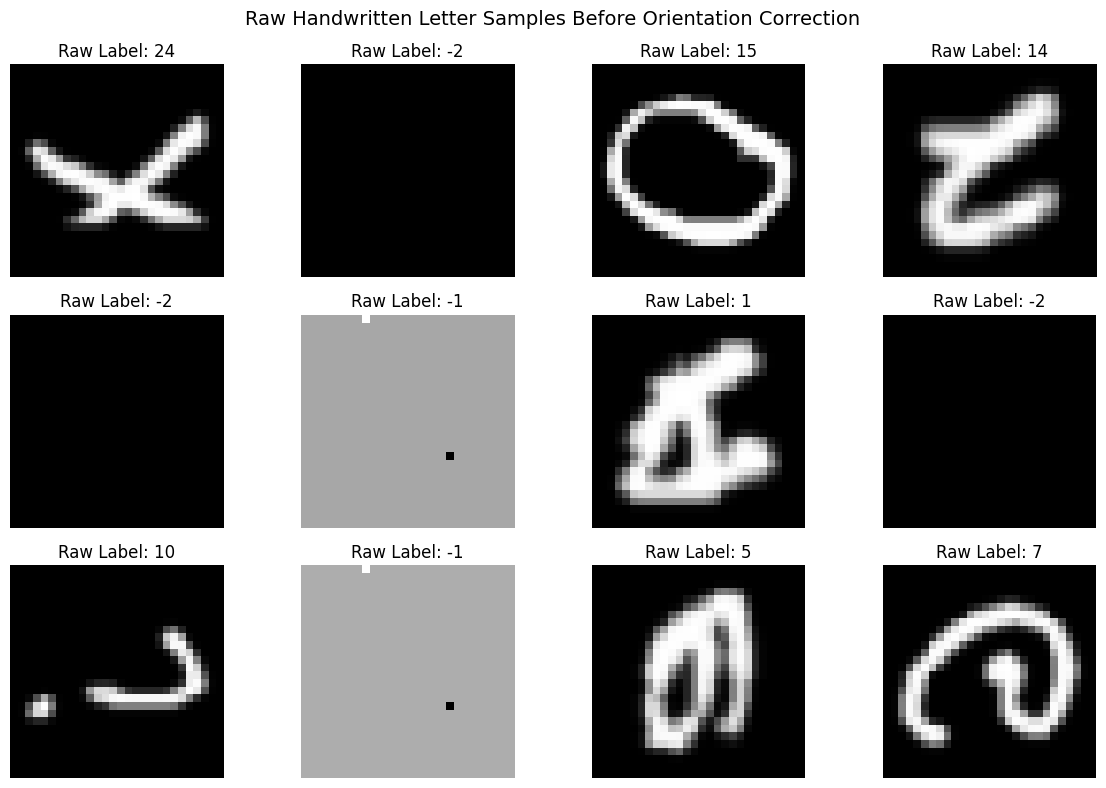

In [107]:
# Display raw handwritten letter samples before preprocessing

plt.figure(figsize=(12,8))


# Display 12 sample images from the dataset
for i in range(12):

    # Create subplot grid (3 rows × 4 columns)
    plt.subplot(3,4,i+1)

    # Reshape the 784 pixel values into a 28×28 image
    image = df.iloc[i, 1:].values.reshape(28,28)

    # Display the handwritten image in grayscale
    plt.imshow(image, cmap='gray')

    # Display the corresponding raw label
    plt.title(f"Raw Label: {df.iloc[i,0]}")

    # Remove axis values for cleaner visualisation
    plt.axis('off')


# Add an overall title to the figure
plt.suptitle(
    "Raw Handwritten Letter Samples Before Orientation Correction",
    fontsize=14
)

# Adjust subplot spacing
plt.tight_layout()

# Display the figure
plt.show()

## Insights

The raw handwritten letter samples show that the EMNIST images are initially stored in a rotated and transposed orientation.

Although several handwritten characters remain partially recognisable, the incorrect alignment causes many letters to appear sideways or distorted. This confirms that orientation correction is necessary before CNN model training.

In addition, some samples contain invalid labels such as `-1` and `-2`, with several images appearing blank or corrupted. This indicates the presence of invalid records within the dataset that must be removed during the data cleaning stage.

The visualisation also demonstrates the natural variability in handwriting styles, including differences in stroke thickness, shape, and character structure. These variations increase the complexity of handwritten character recognition and highlight the importance of robust preprocessing and feature extraction techniques.

Overall, these findings emphasise the importance of preprocessing steps such as:

- Data cleaning
- Label correction
- Image normalisation
- Orientation correction

Without proper preprocessing, the CNN model may learn incorrect spatial patterns and noisy features, which could negatively affect classification accuracy and generalisation performance.

## Step 4. Data Cleaning

After loading the dataset, data cleaning was performed to remove invalid or corrupted records before CNN model training.

The EMNIST Letters dataset should only contain class labels ranging from 1 to 26, where each value represents a valid handwritten alphabet character. However, earlier inspection revealed the presence of invalid labels such as `-1` and `-2`, indicating corrupted or unusable samples.

Training a CNN model using invalid records may negatively affect feature learning, reduce classification accuracy, and introduce noise into the dataset. Therefore, these invalid samples must be removed to ensure reliable and consistent model training.

In this step, the dataset was filtered to retain only valid handwritten letter classes between 1 and 26. The dataset size and unique label values were then rechecked to confirm successful cleaning.

This process improves overall data quality and ensures that the CNN models are trained using only valid handwritten character images.

In [108]:
# Rename the first column as "label"
# to improve dataset readability
df.rename(columns={0: "label"}, inplace=True)


# Store the original dataset size
# before cleaning
original_rows = len(df)


# Display unique labels before cleaning
# to identify invalid values
print("Unique Labels Before Cleaning:")
print(sorted(df["label"].unique()))


# Keep only valid labels
# between 1 and 26
df = df[df["label"].between(1, 26)]

# Reset index after removing invalid rows
df = df.reset_index(drop=True)


# Calculate the number of removed rows
removed_rows = original_rows - len(df)


# Display cleaned dataset dimensions
print("\nDataset Shape After Cleaning:", df.shape)


# Display remaining unique labels
# after cleaning
print("\nUnique Labels After Cleaning:")
print(sorted(df["label"].unique()))


# Display total removed records
print("\nRows Removed:", removed_rows)

Unique Labels Before Cleaning:
[-2, -1, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]

Dataset Shape After Cleaning: (88800, 785)

Unique Labels After Cleaning:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]

Rows Removed: 10240


## Insights

Before cleaning, the dataset contained invalid labels such as `-1` and `-2`, which do not correspond to any valid handwritten alphabet class.

A total of 10,240 invalid or corrupted records were removed during the cleaning process. As a result, the dataset size was reduced from 99,040 samples to 88,800 valid handwritten letter images.

After filtering, all remaining labels fall within the valid range of 1 to 26, confirming that the dataset was successfully cleaned and is now suitable for CNN model training.

Removing invalid records is an important preprocessing step because corrupted samples may introduce noise and incorrect spatial learning patterns into the model. If left unremoved, these records could negatively affect:

- Feature extraction
- Model convergence
- Classification accuracy
- Generalisation performance

The cleaned dataset now provides a more reliable foundation for preprocessing, feature learning, and handwritten letter classification.

## Step 4.1 EMNIST Image Orientation Correction

The EMNIST dataset images are stored in a transposed orientation due to the dataset formatting inherited from the original MNIST conversion process.

As a result, the handwritten characters appear rotated or incorrectly aligned when displayed directly from the raw dataset. To improve visual interpretability during exploratory analysis and evaluation, image transposition was applied so that handwritten letters appear in a human-readable upright format throughout the notebook.

A 90-degree clockwise rotation was applied to correct the orientation of the handwritten characters for proper visualisation and analysis.

In [109]:
def fix_emnist_orientation(image):

    # Rotate image 90 degrees clockwise
    return np.rot90(image, k=3)

## Insights

The EMNIST handwritten images were initially stored in a transposed orientation, causing many characters to appear rotated or incorrectly aligned during visualisation.

Applying orientation correction improves the readability and interpretability of the handwritten characters, allowing visualisations to more accurately represent the actual letter structures.

Correct image orientation is important during exploratory analysis and evaluation because improperly aligned images may make it more difficult to interpret handwritten patterns, analyse model predictions, and investigate classification errors.

### Note on EMNIST Image Orientation

The EMNIST dataset images are stored in a transposed orientation due to the dataset formatting inherited from the original MNIST conversion process.

To improve visual interpretability during exploratory analysis and evaluation, image transposition was applied during visualisation so that handwritten letters appear in a human-readable upright format throughout the notebook.

## Step 5. Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to better understand the cleaned dataset before building the CNN models.

In this section, the class distribution was analysed to determine whether the dataset is balanced across all 26 handwritten letter classes. Understanding class distribution is important because severe class imbalance may bias the CNN model towards classes with more training samples, negatively affecting classification performance for underrepresented classes.

The distribution of handwritten letter images was examined both numerically and visually to verify dataset balance. A balanced dataset helps ensure that the CNN model can learn representative features for all classes more fairly and effectively.

In addition, EDA helps identify potential dataset issues such as class imbalance, corrupted samples, and label inconsistencies before preprocessing and model training, enabling more reliable deep learning development.

## Step 5.1 Class Distribution

The distribution of handwritten letter classes was analysed to determine whether the dataset is balanced across all 26 classes.

A balanced dataset is important because severe imbalance may cause the CNN model to become biased towards classes with more training samples, leading to poorer classification performance for underrepresented classes.

The number of handwritten images belonging to each class was calculated to evaluate the consistency of class representation throughout the dataset.

In [110]:
# Count the number of handwritten images
# belonging to each letter class
label_counts = df["label"].value_counts().sort_index()


# Display the number of images
# for each class label
print("Number of Images per Class:")
print(label_counts)


# Display the minimum class count
print("\nMinimum Class Count:", label_counts.min())


# Display the maximum class count
print("Maximum Class Count:", label_counts.max())


# Calculate the difference between
# the largest and smallest class
print("Difference:", label_counts.max() - label_counts.min())

Number of Images per Class:
label
1     3396
2     3396
3     3419
4     3398
5     3437
6     3394
7     3385
8     3424
9     3428
10    3402
11    3438
12    3415
13    3402
14    3365
15    3408
16    3430
17    3435
18    3419
19    3392
20    3436
21    3419
22    3422
23    3423
24    3437
25    3453
26    3427
Name: count, dtype: int64

Minimum Class Count: 3365
Maximum Class Count: 3453
Difference: 88


## Insights

The numerical analysis shows that the EMNIST Letters dataset is well balanced across all 26 handwritten letter classes.

The smallest class contains 3,365 images, while the largest class contains 3,453 images. The difference between the minimum and maximum class counts is only 88 images, indicating very low class imbalance across the dataset.

This balanced distribution is beneficial for CNN training because the model is less likely to become biased towards specific classes during learning.

As a result, the dataset is considered suitable for multi-class handwritten letter classification, and overall accuracy can be used as a reliable evaluation metric for model performance.

The relatively consistent class distribution also helps improve:
- Fair feature learning across classes
- Model stability during training
- Generalisation capability on unseen handwritten samples

## Step 5.2 Class Distribution Visualisation

A bar chart was plotted to visually examine the distribution of handwritten letter classes in the EMNIST Letters dataset.

Visualisation provides a clearer understanding of class representation patterns and allows dataset balance to be assessed more intuitively than numerical statistics alone.

A balanced class distribution is important because it enables the CNN model to learn representative features for each handwritten letter class more fairly during training, reducing the likelihood of prediction bias towards specific classes.

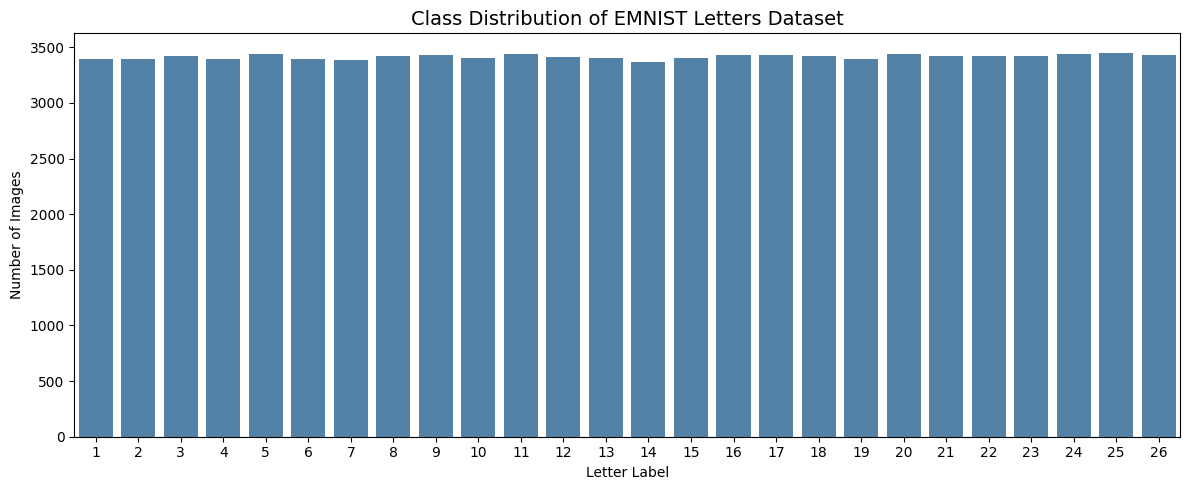

In [111]:
# Create figure for class distribution visualisation
plt.figure(figsize=(12,5))


# Plot bar chart showing the number of images
# for each handwritten letter class
sns.barplot(
    x=label_counts.index,
    y=label_counts.values,
    color='steelblue'
)


# Add chart title and axis labels
plt.title(
    "Class Distribution of EMNIST Letters Dataset",
    fontsize=14
)

plt.xlabel("Letter Label")
plt.ylabel("Number of Images")


# Keep x-axis labels horizontal
plt.xticks(rotation=0)


# Adjust layout for cleaner spacing
plt.tight_layout()


# Display the chart
plt.show()

## Insights

The bar chart visually confirms that the EMNIST Letters dataset is relatively balanced across all 26 handwritten letter classes.

The heights of the bars are highly consistent, indicating that no single class dominates the dataset. This balanced distribution reduces the likelihood of prediction bias during CNN training.

The visualisation also supports the earlier numerical analysis by showing that the differences between class frequencies are minimal across all classes.

Overall, the dataset appears highly suitable for multi-class handwritten letter classification, as all classes are sufficiently represented for effective feature learning, model training, and performance evaluation.

The balanced distribution may also contribute to improved model generalisation capability, since the CNN model is exposed to a relatively equal number of training samples for each handwritten letter class.

## 5.3 Sample Handwritten Letter Images (Before Orientation Correction)

A subset of handwritten letter images was visualised to further examine how raw pixel values represent handwritten characters in the EMNIST Letters dataset.

Each handwritten image consists of 784 pixel intensity values, which were reshaped into a 28 × 28 grayscale image for visualisation.

Visual inspection is an important step in image-based deep learning projects because orientation and structural issues may not always be fully revealed through numerical analysis alone.

At this stage, the handwritten images are displayed before orientation correction and image preprocessing are applied.

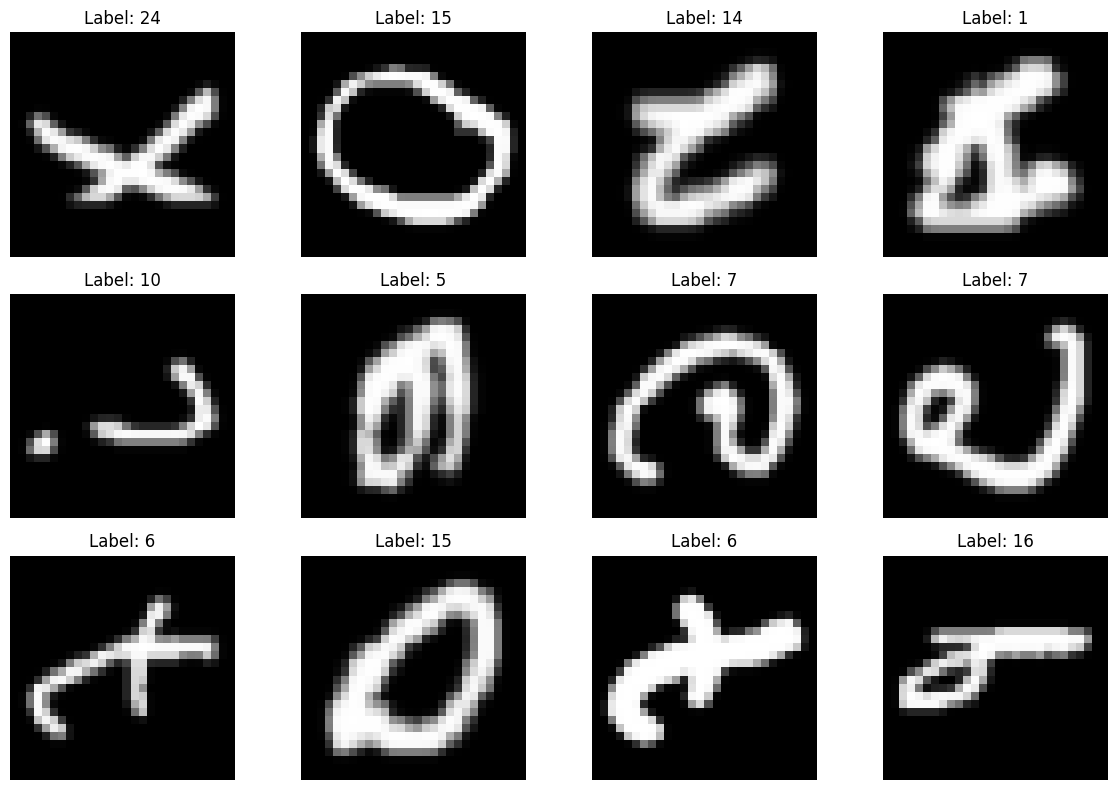

In [112]:
# Display sample handwritten letter images
# before orientation correction

plt.figure(figsize=(12,8))


# Display 12 sample handwritten images
for i in range(12):

    # Create subplot grid
    # (3 rows × 4 columns)
    plt.subplot(3,4,i+1)

    
    # Reshape the 784 pixel values
    # into a 28 × 28 grayscale image
    image = df.iloc[i, 1:].values.reshape(28,28)

    
    # Display the handwritten image
    plt.imshow(image, cmap='gray')

    
    # Display the corresponding class label
    plt.title(f"Label: {df.iloc[i,0]}")

    
    # Remove axis values for cleaner visualisation
    plt.axis('off')


# Adjust subplot spacing automatically
plt.tight_layout()


# Display all sample images
plt.show()

## Insights

The visualisation further confirms that the EMNIST handwritten letter images are initially stored in a rotated and transposed orientation.

Although many handwritten characters remain partially recognisable, the incorrect alignment may negatively affect CNN feature extraction and spatial pattern learning if left uncorrected.

The images also demonstrate natural variability in handwriting style, including differences in stroke thickness, curvature, and character structure. This highlights the complexity of handwritten letter classification and reinforces the importance of robust CNN feature learning.

These observations support the need for orientation correction and preprocessing before CNN model training.

## Step 5.4 Label-to-Letter Mapping

The EMNIST dataset stores handwritten letter classes using numerical labels ranging from 1 to 26. To improve readability and interpretability during visualisation and model evaluation, the numerical labels were converted into their corresponding alphabet characters.

This allows handwritten image samples, confusion matrices, prediction outputs, and error analysis results to display meaningful letter representations instead of numeric class identifiers.

In [113]:
# Create label-to-letter mapping
label_map = {
    i: chr(64 + i)
    for i in range(1, 27)
}

# Display sample mapping
print(label_map)

{1: 'A', 2: 'B', 3: 'C', 4: 'D', 5: 'E', 6: 'F', 7: 'G', 8: 'H', 9: 'I', 10: 'J', 11: 'K', 12: 'L', 13: 'M', 14: 'N', 15: 'O', 16: 'P', 17: 'Q', 18: 'R', 19: 'S', 20: 'T', 21: 'U', 22: 'V', 23: 'W', 24: 'X', 25: 'Y', 26: 'Z'}


## Insights

The label mapping successfully converts numerical EMNIST class labels into human-readable alphabet characters.

This improves the interpretability of visualisations and evaluation outputs throughout the project, especially during:

- sample image visualisation
- prediction analysis
- confusion matrix interpretation
- error analysis

Using alphabet labels instead of numeric identifiers also improves presentation quality and makes the notebook easier to understand from both an academic and practical perspective.

## 5.5 Image Orientation Correction

The EMNIST handwritten letter images are stored in a transposed orientation by default. As observed earlier, the raw handwritten images appear misaligned when visualised directly.

Image orientation correction is an important preprocessing step because Convolutional Neural Networks (CNNs) learn spatial features such as:

- edges
- curves
- stroke directions
- character structures

Incorrectly oriented images may reduce spatial feature consistency and negatively affect feature extraction and classification performance.

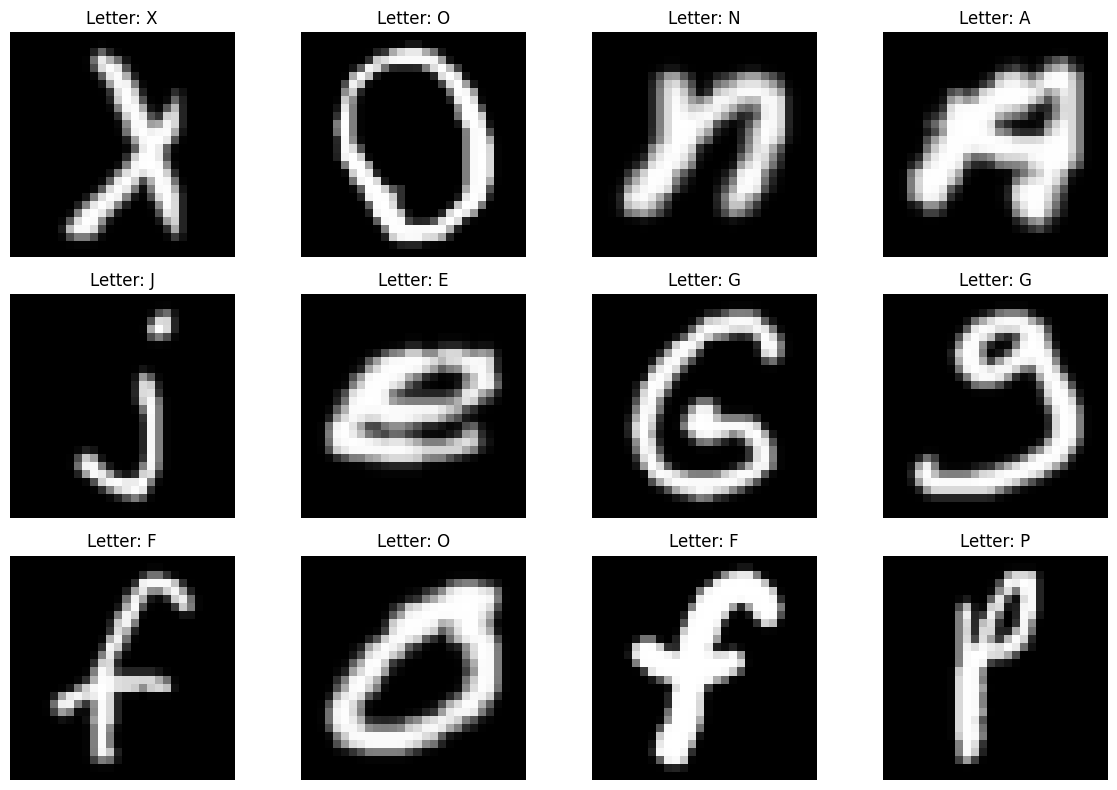

In [114]:
# Function to correct EMNIST image orientation
def fix_emnist_orientation(image):

    # Rotate 90 degrees clockwise
    # and flip horizontally
    return np.fliplr(np.rot90(image, k=3))


# Display corrected handwritten letter images
# after orientation correction

plt.figure(figsize=(12,8))


# Display 12 corrected handwritten images
for i in range(12):

    # Create subplot grid
    # (3 rows × 4 columns)
    plt.subplot(3,4,i+1)

    
    # Reshape the 784 pixel values
    # into a 28 × 28 grayscale image
    image = df.iloc[i, 1:].values.reshape(28,28)

    
    # Apply orientation correction
    image = fix_emnist_orientation(image)

    
    # Display corrected image
    plt.imshow(image, cmap='gray')

    
    # Display corresponding class label
    plt.title(f"Letter: {label_map[df.iloc[i,0]]}")

    
    # Remove axis values
    plt.axis('off')


# Adjust subplot spacing automatically
plt.tight_layout()


# Display corrected images
plt.show()

### Insight

The corrected handwritten letter images now appear in proper upright orientation, making the EMNIST dataset visually interpretable for both human analysis and CNN training.

The transpose operation successfully restores the handwritten characters into a readable format while preserving the original handwritten stroke structures and spatial relationships.

This correction is important because CNN models rely heavily on spatial feature learning, including:

- edge detection
- curve recognition
- stroke orientation
- structural feature extraction

Using properly oriented handwritten images helps ensure greater consistency throughout:

- exploratory data analysis
- CNN preprocessing
- data augmentation
- model training
- model evaluation

The corrected images also provide clearer visual interpretation of handwritten character variations across different writing styles within the EMNIST dataset.

Overall, the orientation correction improves preprocessing consistency and establishes a cleaner foundation for subsequent CNN training and handwritten letter classification experiments.

## 5.5 Global EMNIST Orientation Correction for CNN Training

After visually confirming the EMNIST image orientation issue, global orientation correction is applied before CNN preprocessing and model training.

Although the raw EMNIST dataset stores handwritten letters in a transposed orientation, training CNN models directly on incorrectly oriented images may reduce preprocessing consistency and affect spatial feature learning.

To ensure a fully consistent deep learning workflow, all handwritten images are transposed into upright human-readable orientation before:

- train-test splitting
- CNN model training
- data augmentation
- model evaluation
- error analysis

This ensures that all subsequent experiments, visualisations, and CNN models operate on consistently oriented handwritten letter images throughout the project.

After orientation correction, the handwritten images are reshaped into CNN-compatible format `(28 × 28 × 1)` for convolutional neural network training.

In [115]:
# Extract image features
X = df.iloc[:, 1:].values

# Extract labels
y = df.iloc[:, 0].values


# Convert labels from 1-26 to 0-25
y = y - 1


# Reshape into 28x28 images
X = X.reshape(-1,28,28)


# Apply global orientation correction
X = np.array([
    fix_emnist_orientation(image)
    for image in X
])


# Reshape for CNN input
X = X.reshape(-1,28,28,1)


# Display final dataset shape
print("Final Image Shape:", X.shape)

# Display label shape
print("Label Shape:", y.shape)

Final Image Shape: (88800, 28, 28, 1)
Label Shape: (88800,)


### Insight

Global orientation correction ensures that all handwritten letter images used throughout the project remain consistently aligned for CNN preprocessing, training, evaluation, and visualisation.

By applying the transpose operation before train-test splitting and CNN training, the entire deep learning pipeline operates on upright handwritten letter images rather than rotated EMNIST representations.

This preprocessing step improves overall workflow consistency across:

- exploratory data analysis
- data augmentation
- CNN training
- prediction visualisation
- misclassification analysis

Using correctly oriented handwritten images also allows the CNN model to learn spatial handwriting patterns more naturally, including:

- edge structures
- stroke directions
- curved patterns
- character shapes

Although convolutional neural networks are capable of learning from consistently rotated datasets, training on upright handwritten letters provides a cleaner, more interpretable, and academically stronger preprocessing workflow.

Overall, the global orientation correction establishes a fully consistent foundation for all subsequent CNN experiments and handwritten letter classification tasks performed in this project.

## Step 6. Data Preprocessing

Before training the Convolutional Neural Network (CNN) models, the dataset must be transformed into a format suitable for deep learning.

Raw image data cannot be directly used for CNN training because neural networks require structured numerical inputs with consistent dimensions and properly scaled feature values.

The following preprocessing steps were performed in this section:

### Feature-Label Separation
The dataset was divided into:
- Input features (`X`)
- Target labels (`y`)

### Label Adjustment
Labels were converted from the range `1–26` to `0–25` to match the indexing format required for multi-class classification in TensorFlow/Keras.

### Normalization
Pixel intensity values were scaled from the range `0–255` to `0–1` to improve numerical stability, convergence speed, and optimisation efficiency during CNN training.

### Reshaping
Each image was reshaped into a `28 × 28` format and expanded into a `28 × 28 × 1` tensor to include the grayscale channel dimension required by CNN layers.

### Orientation Correction
Images were rotated to restore the correct handwritten orientation before CNN feature extraction.

### One-Hot Encoding
Labels were converted into one-hot encoded vectors to support multi-class classification using the softmax output layer.

These preprocessing steps ensure that the handwritten image dataset is properly structured, numerically stable, and optimised for CNN model training.

In [116]:
# Separate features and labels
X = df.drop("label", axis=1).values
y = df["label"].values


# Convert labels from 1–26 to 0–25
y = y - 1


# Normalize pixel values to range 0–1
X = X / 255.0


# Reshape images into 28×28 format
X = X.reshape(-1, 28, 28)

# Correct EMNIST image orientation
# Rotate images clockwise to restore
# proper handwritten orientation
X = np.array([
    np.rot90(img, k=3)
    for img in X
])

# Add grayscale channel dimension
X = X.reshape(-1, 28, 28, 1)


# One-hot encode labels
y = to_categorical(y, num_classes=26)


# Display processed dataset information
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Pixel range:", X.min(), "to", X.max())

X shape: (88800, 28, 28, 1)
y shape: (88800, 26)
Pixel range: 0.0 to 1.0


## Insights

After preprocessing, the dataset was successfully transformed into a format suitable for CNN model training.

The input images were reshaped into tensors with dimensions of `28 × 28 × 1`, which matches the input structure required for grayscale image classification using convolutional neural networks.

The labels were also successfully converted into one-hot encoded vectors containing 26 output classes, allowing the model to perform multi-class handwritten letter classification using softmax activation.

Pixel intensity values were normalised to the range `0–1`, which improves numerical stability and helps the CNN model train more efficiently by reducing the risk of excessively large gradient updates during optimisation.

The orientation correction process ensures that handwritten characters are consistently aligned before feature extraction, allowing the CNN model to learn more meaningful spatial relationships and stroke patterns during training.

Overall, these preprocessing steps prepare the EMNIST dataset for stable and effective deep learning training while improving model convergence, feature learning quality, and classification performance.

## Step 7. Train-Test Split

After preprocessing, the dataset was divided into training and testing sets to evaluate the CNN models on unseen handwritten letter images.

The training set is used for model learning, while the testing set is reserved exclusively for final performance evaluation.

An 80:20 split ratio was applied:
- 80% of the dataset was used for training
- 20% of the dataset was used for testing

Stratified sampling was applied during the splitting process to preserve the class distribution across both datasets. This ensures that all 26 handwritten letter classes remain proportionally represented in both the training and testing sets, enabling fair and reliable model evaluation.

A fixed random seed was also used to ensure reproducibility of the dataset split across multiple experimental runs.

Proper train-test splitting is important because it allows the CNN models to be evaluated on unseen data, providing a more reliable measure of generalisation performance while reducing the risk of data leakage.

In [117]:
# Import train_test_split function
# from scikit-learn
from sklearn.model_selection import train_test_split


# Split dataset into training and testing sets
# 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# Display training and testing
# dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)


# Display sample labels from the
# training dataset after splitting
print("\nSample Training Labels:")
print(np.argmax(y_train, axis=1)[:10])


# Display sample labels from the
# testing dataset after splitting
print("\nSample Testing Labels:")
print(np.argmax(y_test, axis=1)[:10])

X_train shape: (71040, 28, 28, 1)
X_test shape : (17760, 28, 28, 1)
y_train shape: (71040, 26)
y_test shape : (17760, 26)

Sample Training Labels:
[ 8 14 10 14 15  9 15  8 24  1]

Sample Testing Labels:
[ 6 20 13 17 23 15  5 18 14  7]


## Insights

The dataset was successfully divided into training and testing sets using an 80:20 split ratio.

The training dataset contains 71,040 handwritten images, while the testing dataset contains 17,760 images reserved for final model evaluation.

Both datasets preserve the same image dimensions of `28 × 28 × 1` and maintain the same one-hot encoded label structure consisting of 26 output classes.

The use of stratified sampling ensures that the class distribution remains balanced across both datasets. This is important because it prevents certain handwritten letter classes from being overrepresented or underrepresented in either split, enabling fairer and more reliable model evaluation.

Separating the dataset into training and testing subsets is an essential step in deep learning because it allows the CNN models to be evaluated on previously unseen handwritten images. This provides a more realistic measure of the model’s generalisation capability and helps reduce the risk of overly optimistic evaluation results caused by testing on training data.

Maintaining a dedicated testing dataset also ensures that the final evaluation reflects the true performance of the CNN models under unseen conditions.

## Step 8. Baseline CNN Model

A Convolutional Neural Network (CNN) was constructed as the baseline model for handwritten letter classification.

The purpose of the baseline model is to establish an initial reference performance before applying more advanced optimisation techniques such as:
- Data augmentation
- Batch Normalization
- Dropout regularisation

CNNs are highly effective for image classification tasks because they automatically learn spatial features such as edges, curves, stroke patterns, and handwritten character structures directly from image data.

---

## Model Architecture

The baseline CNN architecture consists of the following components:

### Convolutional Layers
Convolutional layers using `3 × 3` filters were used to extract important local visual features from handwritten letter images.

The number of filters increases from `32 → 64`, allowing deeper layers to learn increasingly complex feature representations.

### MaxPooling Layers
MaxPooling layers were used to reduce spatial dimensions and computational complexity while preserving important visual information.

### Flatten Layer
The Flatten layer converts the extracted feature maps into a one-dimensional feature vector before classification.

### Dense Layer
A Dense layer containing 128 neurons was used to learn higher-level feature relationships before final classification.

### Output Layer
The output layer contains 26 neurons corresponding to the 26 handwritten letter classes.

Softmax activation was applied to produce probability distributions across all output classes.

---

## Model Compilation

The model was compiled using:
- Adam optimizer for adaptive gradient optimisation
- Categorical crossentropy loss for multi-class classification
- Accuracy as the primary evaluation metric

This baseline CNN model serves as the foundation for later performance comparisons and architectural improvements.

In [118]:
# Import required Keras modules
# for CNN model construction
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense


# Create a Sequential CNN model
model = Sequential()


# First convolutional layer
# 32 filters with 3×3 kernel
# ReLU activation introduces non-linearity
# input_shape defines image dimensions
model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(28,28,1)
    )
)


# First max pooling layer
# Reduces spatial dimensions
# and computational complexity
model.add(
    MaxPooling2D((2,2))
)


# Second convolutional layer
# Uses more filters (64)
# to learn more complex features
model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu'
    )
)


# Second max pooling layer
model.add(
    MaxPooling2D((2,2))
)


# Flatten feature maps into
# a one-dimensional vector
# before dense layers
model.add(Flatten())


# Fully connected dense layer
# Learns higher-level feature relationships
model.add(
    Dense(
        128,
        activation='relu'
    )
)


# Output layer
# 26 neurons correspond to
# the 26 handwritten letter classes
# Softmax converts outputs into probabilities
model.add(
    Dense(
        26,
        activation='softmax'
    )
)


# Compile CNN model
# Adam optimizer for adaptive learning
# categorical_crossentropy for multi-class classification
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# Display model architecture summary
model.summary()

Model: "sequential_22"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_50 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_44 (MaxPoolin  (None, 13, 13, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_51 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_45 (MaxPoolin  (None, 5, 5, 64)         0         
 g2D)                                                            
                                                                 
 flatten_22 (Flatten)        (None, 1600)              0         
                                                                 
 dense_44 (Dense)            (None, 128)             

## Insights

The baseline CNN model contains approximately 227,098 trainable parameters.

The architecture is relatively lightweight while remaining capable of learning important spatial patterns from handwritten letter images.

The convolutional layers progressively extract both low-level and high-level visual features such as:
- Edges
- Curves
- Stroke directions
- Handwritten character structures

Increasing the number of filters from 32 to 64 enables deeper layers to capture more complex feature representations.

The MaxPooling layers reduce spatial dimensions, helping to lower computational cost and reduce overfitting risk while preserving important visual information.

The Flatten layer transforms the extracted feature maps into a one-dimensional vector, allowing the dense layers to perform higher-level classification learning.

The Dense layer with 128 neurons learns complex feature relationships before the final Softmax output layer produces probability distributions across all 26 handwritten letter classes.

Softmax activation is important because it converts the network outputs into probabilities whose total sum equals 1, allowing the CNN model to determine the most likely handwritten letter class for each image.

Overall, the baseline CNN model provides a strong starting point for handwritten character recognition while maintaining manageable computational complexity.

This model also serves as an important benchmark for evaluating the effectiveness of later improvements such as data augmentation, Batch Normalization, and Dropout regularisation.

## Step 9. Train Baseline CNN Model

The baseline CNN model was trained using the prepared training dataset to learn handwritten letter patterns and perform multi-class classification.

During training, the model iteratively updates its weights through backpropagation and gradient-based optimisation to minimise classification error.

To improve training stability, reduce overfitting, and preserve the best-performing model, several training strategies were applied.

---

## Training Strategies

### Validation Split
20% of the training dataset was reserved as a validation set during training.

The validation dataset is not used for weight updates. Instead, it is used to monitor the model’s generalisation performance on unseen data after each training epoch.

### EarlyStopping
EarlyStopping was used to automatically terminate training if the validation loss did not improve for several consecutive epochs.

This helps:
- Reduce overfitting
- Reduce unnecessary computational cost
- Improve training efficiency

The best-performing model weights based on validation loss are automatically restored once training stops.

### ModelCheckpoint
ModelCheckpoint automatically saves the model weights whenever validation accuracy improves.

This ensures that the highest-performing CNN model is preserved throughout training, even if later epochs produce weaker performance.

These training strategies help improve model robustness, training efficiency, and overall generalisation performance.

In [119]:
# Import training callback functions
# used to improve training stability
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint


# Create EarlyStopping callback
# Monitor validation loss during training
# Stop training if validation loss
# does not improve for 3 consecutive epochs
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


# Create ModelCheckpoint callback
# Save the best model based on
# highest validation accuracy
checkpoint = ModelCheckpoint(
    "best_emnist_model.h5",
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)


# Train the baseline CNN model
history = model.fit(

    # Training images and labels
    X_train,
    y_train,

    # Maximum number of training epochs
    epochs=15,

    # Number of samples processed
    # before weight updates
    batch_size=128,

    # Reserve 20% of training data
    # as validation dataset
    validation_split=0.2,

    # Apply training callbacks
    callbacks=[early_stop, checkpoint]
)

Epoch 1/15
444/444 [==============================] - ETA: 0s - loss: 0.7665 - accuracy: 0.7714   
Epoch 1: val_accuracy improved from -inf to 0.86451, saving model to best_emnist_model.h5
444/444 [==============================] - 12s 22ms/step - loss: 0.7665 - accuracy: 0.7714 - val_loss: 0.4199 - val_accuracy: 0.8645
Epoch 2/15
443/444 [============================>.] - ETA: 0s - loss: 0.3364 - accuracy: 0.8918
Epoch 2: val_accuracy improved from 0.86451 to 0.89576, saving model to best_emnist_model.h5
444/444 [==============================] - 7s 15ms/step - loss: 0.3364 - accuracy: 0.8918 - val_loss: 0.3228 - val_accuracy: 0.8958
Epoch 3/15
442/444 [============================>.] - ETA: 0s - loss: 0.2629 - accuracy: 0.9143
Epoch 3: val_accuracy improved from 0.89576 to 0.90336, saving model to best_emnist_model.h5
444/444 [==============================] - 7s 16ms/step - loss: 0.2633 - accuracy: 0.9142 - val_loss: 0.3011 - val_accuracy: 0.9034
Epoch 4/15
444/444 [================

## Insights

The baseline CNN model demonstrates steady and stable learning throughout the training process.

Training accuracy increases consistently across epochs, indicating that the CNN successfully learns meaningful visual features from the handwritten letter images.

At the same time, training loss decreases progressively, showing that the model becomes more effective at minimising classification errors during optimisation.

Validation accuracy improves rapidly during the earlier epochs before gradually stabilising during later epochs. This suggests that the model learns the most important handwritten feature representations during the initial stages of training.

The validation loss also decreases during the early epochs before showing small fluctuations in later epochs. These fluctuations indicate the early signs of overfitting, where improvements in training performance no longer produce substantial gains in generalisation performance.

The use of EarlyStopping helps reduce this issue by automatically stopping training once validation performance no longer improves consistently. In addition, restoring the best-performing weights ensures that the final CNN model retains the strongest validation performance achieved during training.

ModelCheckpoint further improves training reliability by automatically saving the best-performing CNN model whenever validation accuracy increases.

Overall, the training results show that the baseline CNN model successfully learns useful spatial features from handwritten images while maintaining stable generalisation performance on unseen validation data.

## Step 10. Baseline Performance Analysis

The training history of the baseline CNN model was visualised using accuracy and loss curves.

These performance graphs provide important insights into how the CNN model learns throughout the training process.

By comparing training and validation performance across epochs, it becomes possible to analyse:
- Model learning behaviour
- Convergence speed
- Optimisation effectiveness
- Training stability
- Generalisation performance
- Potential overfitting

Accuracy curves show how the model’s prediction performance improves over time, while loss curves show how effectively the optimisation process minimises classification error.

Analysing both graphs together provides a clearer understanding of whether the CNN model is learning meaningful feature representations while maintaining strong performance on unseen validation data.

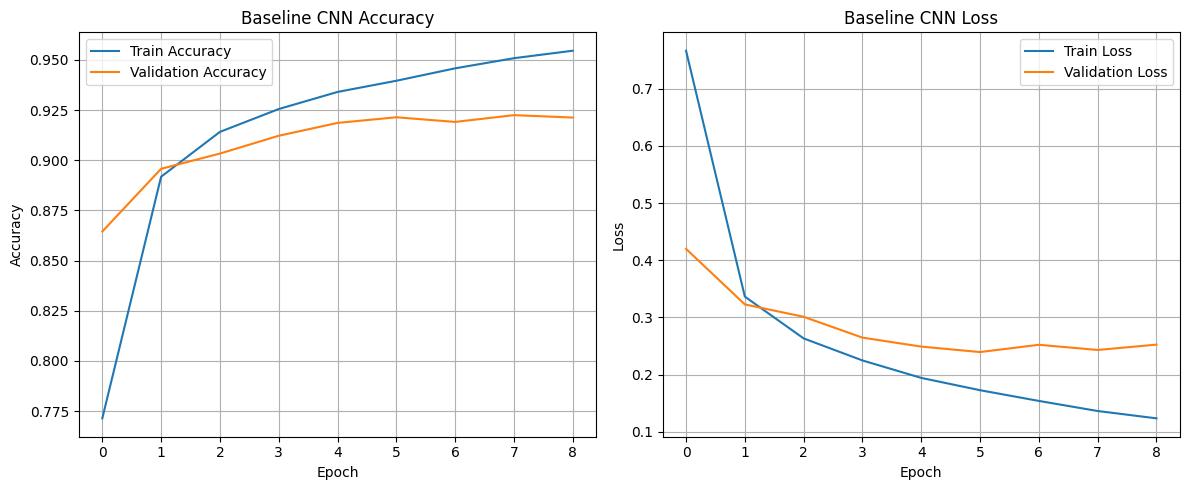

In [120]:
# Create figure for performance graphs
plt.figure(figsize=(12,5))


# Accuracy Graph
# Create subplot for accuracy curves
plt.subplot(1,2,1)


# Plot training accuracy
plt.plot(
    history.history['accuracy'],
    label='Train Accuracy'
)


# Plot validation accuracy
plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)


# Graph title and axis labels
plt.title("Baseline CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")


# Display legend and grid
plt.legend()
plt.grid(True)




# Loss Graph
# Create subplot for loss curves
plt.subplot(1,2,2)


# Plot training loss
plt.plot(
    history.history['loss'],
    label='Train Loss'
)


# Plot validation loss
plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)


# Graph title and axis labels
plt.title("Baseline CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")


# Display legend and grid
plt.legend()
plt.grid(True)


# Improve spacing between graphs
plt.tight_layout()


# Display graphs
plt.show()

## Insights

The accuracy curves show that both training and validation accuracy improve rapidly during the earlier epochs, indicating that the CNN model successfully learns meaningful visual patterns from the handwritten letter images.

Training accuracy increases steadily throughout the training process, demonstrating effective feature extraction and optimisation.

Validation accuracy also improves significantly during the early epochs before gradually stabilising in later epochs. This suggests that the model learns the most important handwritten feature representations during the initial stages of training, while additional training provides only marginal improvements in generalisation performance.

The loss curves further support this learning behaviour.

Training loss decreases consistently across epochs, indicating that the optimisation process effectively minimises classification error during training.

Validation loss also decreases substantially during the earlier epochs before stabilising and showing small fluctuations in later epochs. These fluctuations indicate the early signs of mild overfitting, where improvements in training performance no longer produce equally strong improvements on unseen validation data.

However, the gap between training and validation performance remains relatively moderate, suggesting that the baseline CNN still maintains good generalisation capability.

The use of EarlyStopping further helps control overfitting by restoring the best-performing model weights once validation performance stops improving consistently.

Overall, the baseline CNN demonstrates strong learning capability, stable convergence behaviour, and good generalisation performance, while still leaving room for further improvement through architectural enhancement and regularisation techniques.

## 10.1 Baseline Model Evaluation

After training, the baseline CNN model was evaluated using the unseen test dataset.

The test dataset was not used during training or validation, making it suitable for measuring the model’s true generalisation performance on new handwritten letter images.

The following evaluation metrics were calculated:

- **Test Loss**: Measures the classification error on unseen test data
- **Test Accuracy**: Measures the percentage of correctly classified handwritten letters
- **Test Error Rate**: Measures the percentage of incorrectly classified samples

Evaluating the model on unseen test data is important because it provides a more realistic assessment of how well the CNN model performs in real-world handwritten character recognition tasks.

In [121]:
# Evaluate the trained baseline CNN model
# using the unseen test dataset
test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    verbose=0
)


# Display test loss
print(
    "Test Loss :",
    round(test_loss, 4)
)


# Display test accuracy
print(
    "Test Accuracy :",
    round(test_acc * 100, 2),
    "%"
)


# Calculate and display test error rate
# Error rate = 1 - accuracy
print(
    "Test Error Rate :",
    round((1 - test_acc) * 100, 2),
    "%"
)

Test Loss : 0.239
Test Accuracy : 92.3 %
Test Error Rate : 7.7 %


## Insights

The baseline CNN model achieved a test accuracy of 92.3%, corresponding to a relatively low error rate of 7.7%.

These results indicate that the CNN model successfully learned meaningful spatial and visual features from the handwritten letter images and is able to generalise effectively to previously unseen test data.

The relatively low test loss further suggests that the model performs accurate classification on unseen handwritten letter images while maintaining relatively small prediction errors.

Achieving over 92% accuracy using a relatively simple CNN architecture demonstrates that convolutional neural networks are highly effective for handwritten character recognition tasks. Similar CNN-based approaches have also shown strong performance on EMNIST handwritten character classification problems.

Although the overall performance is strong, some prediction errors still remain. These errors are likely caused by:
- Visually similar handwritten letters
- Variations in handwriting styles
- Unclear stroke patterns
- Ambiguous character shapes

The remaining classification errors also indicate that there is still room for improvement through additional optimisation techniques such as:
- Deeper CNN architectures
- Batch Normalization
- Dropout regularisation
- Data augmentation
- Hyperparameter tuning

Overall, the baseline CNN provides strong classification performance and serves as an effective reference model for evaluating later architectural and optimisation improvements.

## 10.2 Confusion Matrix (Baseline Model)

A confusion matrix was used to analyse the class-wise classification performance of the baseline CNN model across all 26 handwritten letter classes.

Unlike overall accuracy, the confusion matrix provides more detailed insight into how the model performs for each individual class.

The matrix visualises:
- Correctly classified samples (diagonal values)
- Incorrectly classified samples (off-diagonal values)
- Common misclassification patterns between letter classes

This analysis is important because some handwritten letters contain similar visual structures, causing the CNN model to confuse certain classes more frequently than others.

By examining the confusion matrix, it becomes possible to identify:
- Classes with strong classification performance
- Difficult handwritten letters
- Visually similar letter pairs
- Potential weaknesses in feature extraction

This helps provide deeper understanding of the model’s strengths and limitations beyond overall accuracy alone.

555/555 [==============================] - 4s 6ms/step


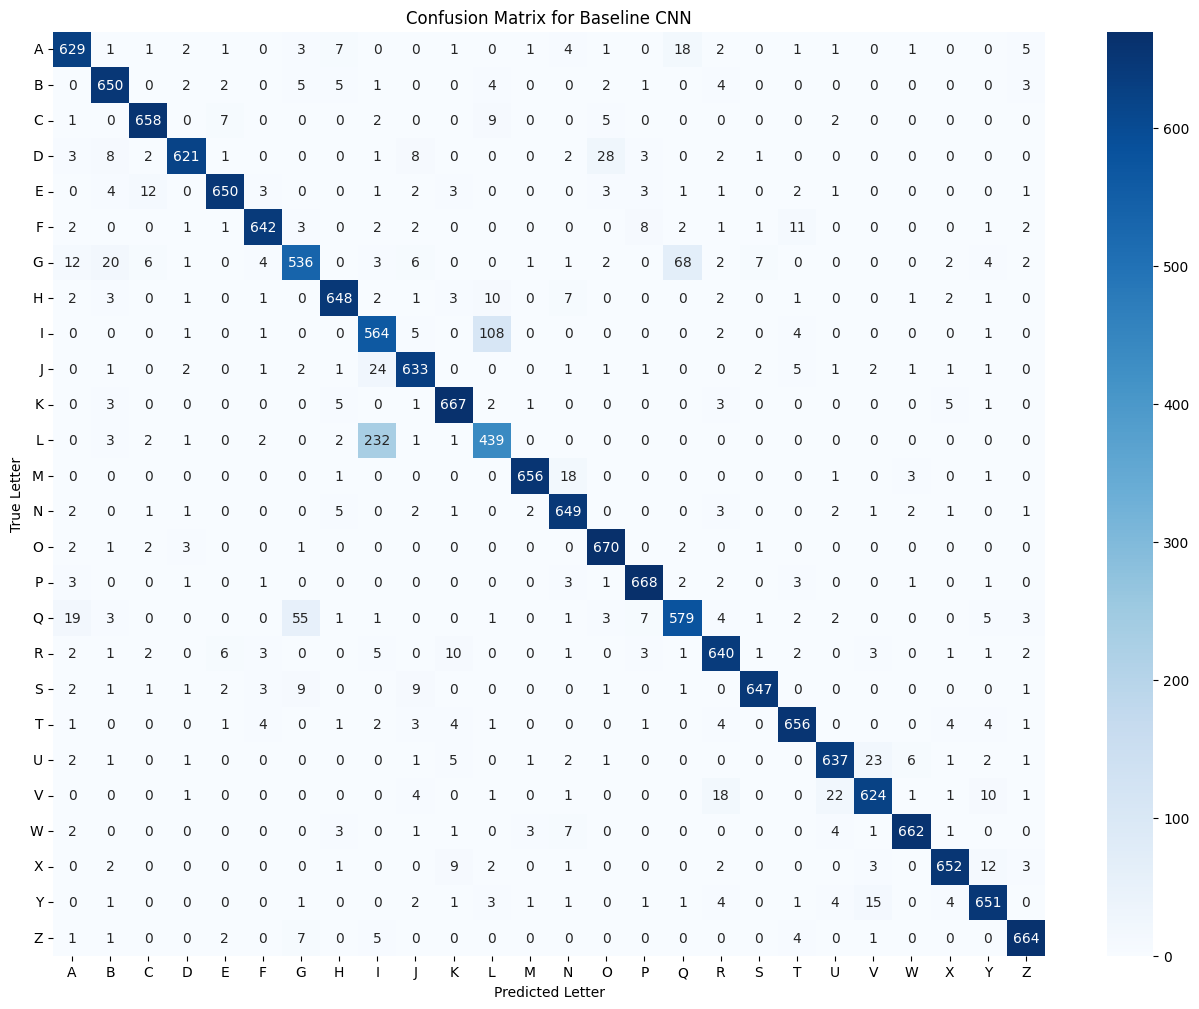

In [122]:
# Predict handwritten letter classes
# using the trained baseline CNN model
y_pred = model.predict(X_test)


# Convert one-hot encoded predictions
# back into class indices
y_pred_classes = np.argmax(y_pred, axis=1)


# Convert one-hot encoded true labels
# back into class indices
y_true_classes = np.argmax(y_test, axis=1)


# Create alphabet labels from A-Z
# for confusion matrix visualisation
import string

class_names = list(string.ascii_uppercase)


# Generate confusion matrix
cm = confusion_matrix(
    y_true_classes,
    y_pred_classes
)


# Plot confusion matrix
plt.figure(figsize=(16,12))

sns.heatmap(
    cm,
    cmap="Blues",

    # Display numbers inside matrix
    annot=True,

    # Display values as integers
    fmt="d",

    # X-axis labels
    xticklabels=class_names,

    # Y-axis labels
    yticklabels=class_names
)


# Add graph title and axis labels
plt.title("Confusion Matrix for Baseline CNN")

plt.xlabel("Predicted Letter")
plt.ylabel("True Letter")


# Keep labels horizontal
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.show()

## Insights

The confusion matrix shows that the majority of predictions are concentrated along the diagonal, indicating that the baseline CNN correctly classifies most handwritten letter images.

This demonstrates that the model has successfully learned meaningful visual and spatial features from the EMNIST handwritten letter dataset.

Although most predictions are correctly classified, several noticeable off-diagonal regions remain for visually similar handwritten letters.

Some of the most significant confusion pairs include:
- I ↔ L
- G ↔ Q
- U ↔ V
- N ↔ H
- C ↔ E

These handwritten letters share similar stroke structures, curves, or overall shapes, making them more difficult for the CNN model to distinguish accurately.

For example:
- The letters I and L may appear visually similar depending on handwriting style and stroke length
- G and Q both contain rounded shapes and closed-loop structures
- U and V may overlap visually when handwritten with curved strokes
- N and H may appear similar when handwriting is distorted or compressed

The confusion matrix also shows that several classes achieve very strong classification performance, with large diagonal values and relatively few misclassifications.

This indicates that the CNN model performs especially well when handwritten characters contain more distinctive spatial features and less overlapping visual structures.

Overall, the confusion matrix demonstrates that the baseline CNN model achieves strong classification capability while also highlighting specific handwritten letter classes that may benefit from:
- Deeper CNN architectures
- Improved feature extraction
- Batch Normalization
- Dropout regularisation
- Additional data augmentation

These findings provide valuable insight into the strengths and limitations of the baseline CNN model before implementing further architectural improvements.

## 10.2.1 Normalized Confusion Matrix

A normalized confusion matrix was generated to further analyse the class-wise classification performance of the baseline CNN model.

Unlike the standard confusion matrix, which displays raw prediction counts, the normalized confusion matrix represents classification results as proportions ranging from 0 to 1.

This provides a clearer comparison of relative classification performance across all handwritten letter classes.

Normalization was performed row-wise, meaning that each row represents the proportion of predictions for a specific true class.

This helps identify:
- Classes with consistently strong classification performance
- Classes with higher relative error rates
- Visually similar handwritten letters that are frequently confused
- Model weaknesses that may not be obvious from overall accuracy alone

The normalized confusion matrix is especially useful in multiclass classification tasks because it allows easier interpretation of prediction behaviour across different classes.

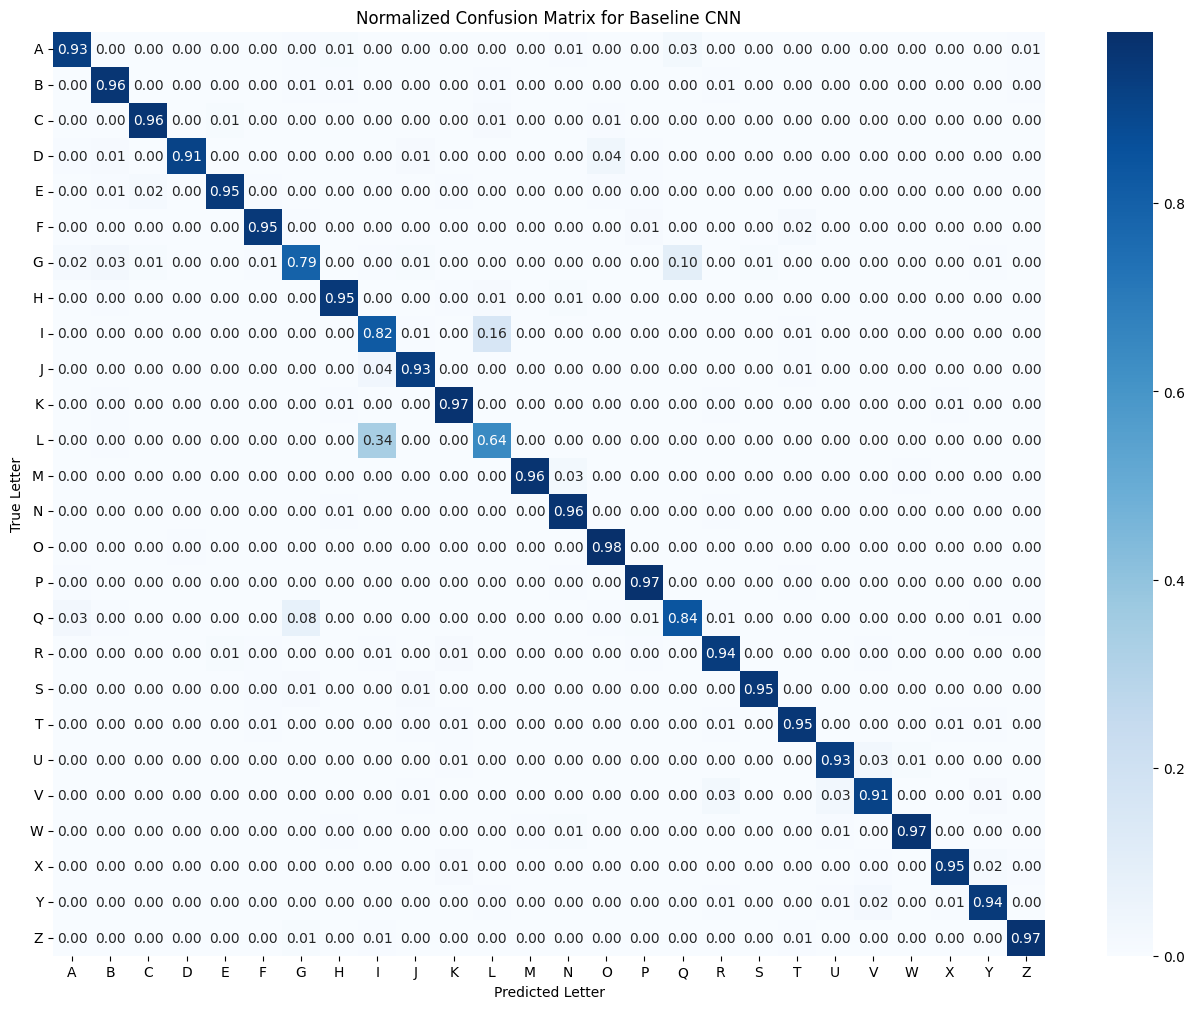

In [123]:
# Normalize confusion matrix row-wise
# to convert raw counts into proportions
cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]


# Plot normalized confusion matrix
plt.figure(figsize=(16,12))

sns.heatmap(
    cm_normalized,

    # Blue color scale
    cmap="Blues",

    # Display values inside cells
    annot=True,

    # Display values with 2 decimal places
    fmt=".2f",

    # Predicted class labels
    xticklabels=class_names,

    # True class labels
    yticklabels=class_names
)


# Add graph title and axis labels
plt.title("Normalized Confusion Matrix for Baseline CNN")

plt.xlabel("Predicted Letter")
plt.ylabel("True Letter")


# Keep axis labels horizontal
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.show()

## Insights

The normalized confusion matrix shows that most handwritten letter classes achieve strong classification performance, as indicated by the high concentration of values along the diagonal.

Many classes achieve class-wise recall values above 90%, demonstrating that the baseline CNN model generalises well across most handwritten character categories.

Compared to the standard confusion matrix, the normalized version provides a clearer representation of the relative classification performance for each class.

This makes it easier to identify which classes experience higher misclassification rates regardless of the total number of samples.

Several classes still show noticeable off-diagonal values, indicating that some handwritten letters are more difficult for the CNN model to distinguish accurately.

For example:
- The letter I is frequently misclassified as L
- The letter L is also commonly predicted as I
- The letters G and Q show visible confusion patterns

These errors are likely caused by similarities in handwritten stroke structures, curved shapes, and writing styles. Similar confusion patterns between I/L and G/Q have also been observed in EMNIST handwritten recognition research. 

The normalized matrix also reveals that several classes achieve exceptionally strong performance with minimal off-diagonal confusion, indicating that certain handwritten letters contain more distinctive spatial features that are easier for the CNN to recognise.

Overall, the normalized confusion matrix confirms that the baseline CNN model achieves strong generalisation performance while also highlighting specific handwritten letter pairs that remain challenging for the model.

These findings provide deeper insight into class-wise model behaviour and help justify the need for later architectural improvements such as Batch Normalization, Dropout regularisation, and enhanced feature extraction.

## 10.2.2 Softmax Probability Analysis

The softmax output probabilities are analysed to better understand the confidence level of the baseline CNN model during prediction.

Unlike the confusion matrix, which only shows the final predicted class, softmax probabilities reveal how strongly the model believes an image belongs to each possible class.

In multi-class classification problems, the softmax activation function converts the model outputs into probability distributions across all 26 handwritten letter classes.

This analysis is especially useful for examining:

- visually similar handwritten letters
- uncertain predictions
- model confidence levels
- misclassification behaviour

For example, handwritten letters such as:

- L and I
- G and Q
- D and O

may receive similar probability scores due to similarities in handwriting structure and stroke patterns.

By analysing the top predicted probabilities for misclassified samples, deeper insight can be obtained into:

- model uncertainty
- feature ambiguity
- decision-making behaviour of the CNN model

This helps explain why certain handwritten letters are more difficult to classify accurately.

In [124]:
# Identify incorrectly classified samples
wrong_indices = np.where(
    y_pred_classes != y_true_classes
)[0]


# Display softmax probabilities
# for the first few incorrect predictions
for idx in wrong_indices[:5]:

    # Get true and predicted classes
    true_class = y_true_classes[idx]
    pred_class = y_pred_classes[idx]

    # Convert class indices to letters
    true_letter = class_names[true_class]
    pred_letter = class_names[pred_class]

    # Retrieve softmax probability vector
    probabilities = y_pred[idx]

    # Get top 5 highest probabilities
    top_5 = np.argsort(probabilities)[-5:][::-1]

    print("="*50)

    print(f"True Letter: {true_letter}")
    print(f"Predicted Letter: {pred_letter}")

    print("\nTop 5 Softmax Probabilities:")

    # Display top predicted probabilities
    for cls in top_5:

        print(
            f"{class_names[cls]}: "
            f"{probabilities[cls]*100:.2f}%"
        )

True Letter: S
Predicted Letter: J

Top 5 Softmax Probabilities:
J: 75.86%
F: 17.57%
I: 6.08%
S: 0.17%
L: 0.14%
True Letter: Q
Predicted Letter: G

Top 5 Softmax Probabilities:
G: 69.38%
Q: 30.56%
A: 0.04%
S: 0.01%
F: 0.01%
True Letter: X
Predicted Letter: V

Top 5 Softmax Probabilities:
V: 56.65%
Y: 36.61%
X: 6.39%
N: 0.11%
U: 0.08%
True Letter: G
Predicted Letter: A

Top 5 Softmax Probabilities:
A: 92.53%
Q: 6.71%
G: 0.38%
O: 0.27%
C: 0.03%
True Letter: L
Predicted Letter: I

Top 5 Softmax Probabilities:
I: 94.28%
L: 5.54%
N: 0.07%
R: 0.03%
P: 0.02%


## Insights

The softmax probability analysis provides deeper insight into the confidence and decision-making behaviour of the baseline CNN model during prediction.

Unlike the confusion matrix, which only shows the final predicted class, the softmax outputs reveal how strongly the model considers multiple possible classes for each handwritten image.

Several misclassified samples show that the CNN model assigns relatively high probabilities to visually similar handwritten letters.

For example:
- The handwritten letter L was predicted as I with 94.28% confidence, while L still retained a probability of 5.54%
- The handwritten letter X was predicted as V with 56.65% confidence, while X also received a substantial probability of 36.61%

These results suggest that certain handwritten letters contain overlapping visual features, making them difficult for the CNN model to distinguish accurately.

The softmax probabilities also reveal different types of model behaviour:
- Some incorrect predictions occur with relatively low confidence and multiple competing classes
- Other misclassifications occur with extremely high confidence, indicating that the handwritten image strongly resembles another class

These confusion patterns are consistent with findings reported in EMNIST handwritten recognition research, where I/L are among the most frequently confused handwritten letter pair.

This analysis provides valuable insight into:
- Model uncertainty
- Visually ambiguous handwriting patterns
- Feature similarity between classes
- CNN decision-making behaviour

Overall, the softmax probability analysis helps explain the misclassification patterns observed earlier in the confusion matrix and normalized confusion matrix while providing deeper understanding of the strengths and limitations of the baseline CNN model.

## 10.3 Classification Report (Baseline Model)

The classification report provides detailed evaluation metrics for each handwritten letter class predicted by the baseline CNN model.

Unlike overall accuracy, the classification report evaluates the model’s performance at the individual class level using:

- precision
- recall
- F1-score

Precision measures how many predicted labels for a class are actually correct.

Recall measures how many actual samples from a class are successfully identified by the model.

F1-score provides a balanced measure between precision and recall, making it especially useful when analysing classification consistency across multiple classes.

These metrics provide deeper insight into:

- class-wise prediction performance
- difficult handwritten letter classes
- model strengths and weaknesses
- classification consistency across all 26 handwritten letters

The classification report helps identify specific classes where the CNN model performs strongly and classes that remain challenging due to similarities in handwritten stroke patterns and character structures.

In [125]:
# Generate classification report
# for all handwritten letter classes
print(

    classification_report(

        # True class labels
        y_true_classes,

        # Predicted class labels
        y_pred_classes,

        # Display class names as A-Z
        target_names=class_names

    )

)

              precision    recall  f1-score   support

           A       0.92      0.93      0.92       679
           B       0.92      0.96      0.94       679
           C       0.96      0.96      0.96       684
           D       0.97      0.91      0.94       680
           E       0.97      0.95      0.96       687
           F       0.97      0.95      0.96       679
           G       0.86      0.79      0.83       677
           H       0.95      0.95      0.95       685
           I       0.67      0.82      0.74       686
           J       0.93      0.93      0.93       680
           K       0.94      0.97      0.96       688
           L       0.76      0.64      0.70       683
           M       0.98      0.96      0.97       680
           N       0.93      0.96      0.95       673
           O       0.93      0.98      0.96       682
           P       0.96      0.97      0.97       686
           Q       0.86      0.84      0.85       687
           R       0.92    

## Insights

The classification report shows that the baseline CNN model achieves strong overall classification performance across most handwritten letter classes.

Most classes achieve precision, recall, and F1-scores above 0.90, indicating that the model is able to correctly identify and distinguish the majority of handwritten characters with high reliability.

Several handwritten letter classes achieve exceptionally strong performance, including:
- M
- O
- P
- W
- Z

These classes achieve very high precision and recall values because their handwritten shapes contain more distinctive visual structures that are easier for the CNN model to recognise.

However, several classes show comparatively weaker performance metrics, particularly:
- I
- L
- G
- Q

For example:
- The letter I achieves a relatively low precision of 0.67
- The letter L achieves a recall of 0.64 and an F1-score of 0.70
- The letter G achieves a recall of 0.79
- The letter Q achieves comparatively lower precision and recall values of approximately 0.84

These lower scores indicate that the CNN model experiences greater difficulty distinguishing between certain visually similar handwritten letters.

The weaker performance is likely caused by:
- Similar stroke patterns
- Overlapping handwritten shapes
- Variations in handwriting styles
- Ambiguous character structures

These findings are consistent with the earlier confusion matrix and softmax probability analyses, which also identified strong confusion patterns between classes such as:
- I ↔ L
- G ↔ Q

Similar confusion behaviour between these handwritten letter pairs has also been reported in the original EMNIST research. 

The overall model accuracy of approximately 92% is consistent with earlier evaluation results obtained from the unseen test dataset.

In addition, the macro average and weighted average scores are highly similar, indicating that the model performs relatively consistently across all handwritten letter classes without strong prediction bias toward any specific category.

This consistency is expected because the EMNIST Letters dataset is relatively balanced across all 26 handwritten letter classes. 

Overall, the classification report confirms that the baseline CNN model achieves strong multi-class classification performance while also highlighting specific handwritten letter classes that may benefit from improved feature extraction and architectural enhancements.

## 10.4 Class-wise Recall Visualisation

A class-wise recall graph is generated to compare the prediction performance of the baseline CNN model across all 26 handwritten letter classes.

Unlike overall accuracy, this visualisation highlights how effectively the model correctly identifies samples from each individual class separately.

The graph helps identify:

- handwritten letters with strong classification performance
- difficult handwritten classes
- consistency of model performance across classes
- potential weaknesses in feature extraction

This visual analysis complements the confusion matrix and classification report by providing a clearer comparison of class-level recall performance.

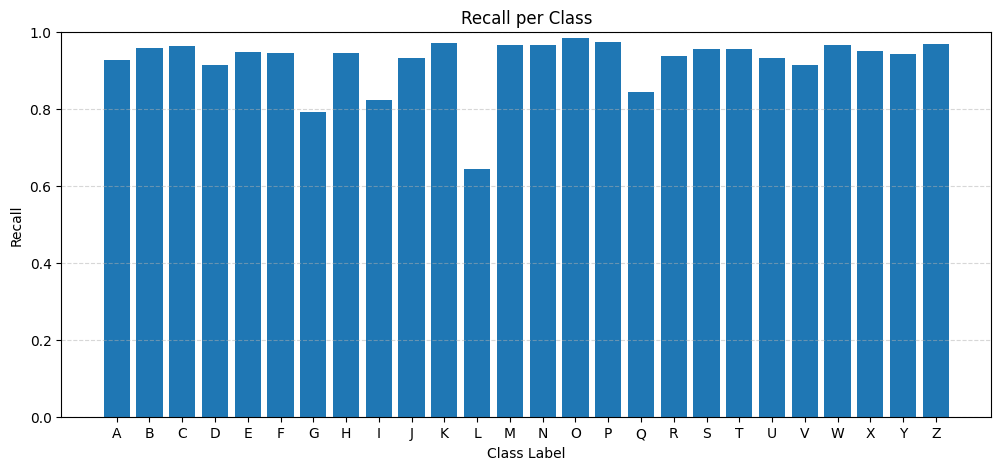

In [126]:
# Store recall values for each class
class_recall = []

# Calculate class-wise recall
for i in range(26):

    # True positives
    correct = cm[i][i]

    # Total actual samples
    total = cm[i].sum()

    # Recall calculation
    recall = correct / total

    # Store recall
    class_recall.append(recall)

# Create figure
plt.figure(figsize=(12,5))

# Plot recall values
plt.bar(range(26), class_recall)

# Display class labels
plt.xticks(range(26), class_names)

# Graph title and labels
plt.title("Recall per Class")
plt.xlabel("Class Label")
plt.ylabel("Recall")

# Y-axis range
plt.ylim(0,1)

# Add horizontal grid
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

## Insight

The class-wise recall graph shows that the baseline CNN model achieves consistently strong performance across most handwritten letter classes.

Many classes achieve recall values above 90%, indicating that the CNN model is highly effective at correctly identifying most handwritten character patterns.

Several classes achieve exceptionally high recall performance, including:

- O
- P
- W
- Z

These handwritten letters contain more distinctive visual structures and stroke patterns, making them easier for the CNN model to classify correctly.

However, several classes demonstrate comparatively weaker classification performance, particularly:

- L
- I
- G
- Q

Among these classes, I and L show noticeably lower recall values, which is consistent with earlier findings from the confusion matrix and classification report.

These lower recall values are likely caused by:

- similarities in handwritten stroke structures
- overlapping character shapes
- variations in handwriting styles
- ambiguous handwritten representations

For example:

- I and L often contain simple vertical stroke patterns
- G and Q may appear visually similar depending on writing style
- some handwritten characters become distorted due to inconsistent pen strokes

The graph also shows that performance differences between classes are relatively moderate overall, indicating that the model generalises reasonably well across the full alphabet dataset.

This visualisation further reinforces the findings observed in the confusion matrix and classification report.

## Step 11. Data Augmentation Experiment

To improve model generalisation performance, data augmentation is applied to artificially increase the diversity of the training images.

Data augmentation helps the CNN model become more robust to variations in handwriting style, orientation, positioning, and scale without requiring additional external training data.

The following augmentation techniques are applied:

- Rotation (±10°) to simulate slight tilts in handwriting
- Width and height shifts (10%) to simulate positional variation
- Zoom (10%) to simulate differences in writing scale

These transformations are intentionally kept relatively small to preserve the original structure of handwritten characters while still introducing realistic variability into the training data.

Data augmentation is expected to:

- improve model generalisation
- reduce overfitting
- increase robustness to handwriting variations
- help the CNN learn more stable feature representations

This experiment investigates whether augmented training data can improve classification performance compared to the baseline CNN model.

In [127]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


# Configure data augmentation settings
# to generate realistic handwriting variations
datagen = ImageDataGenerator(

    # Random rotation up to ±10 degrees
    rotation_range=10,

    # Random horizontal shifting
    width_shift_range=0.1,

    # Random vertical shifting
    height_shift_range=0.1,

    # Random zoom variation
    zoom_range=0.1
)


# Fit augmentation generator on training data
# to prepare transformed image generation
datagen.fit(X_train)

## Insight

The selected data augmentation techniques introduce realistic variations into the handwritten letter images while preserving the overall structure and readability of each character.

Small rotations, positional shifts, and zoom transformations help simulate natural handwriting differences that commonly occur in real-world handwritten data.

These augmentations increase the diversity of the training dataset without requiring additional external images, allowing the CNN model to learn more robust and generalisable visual features.

The augmentation settings are intentionally kept relatively moderate to avoid excessive distortion of handwritten characters. Excessive transformations could distort important stroke structures and potentially alter the semantic identity of certain handwritten letters.

By exposing the CNN model to slightly modified versions of handwritten characters during training, data augmentation helps:

- improve generalisation performance
- reduce overfitting
- increase robustness to handwriting variation
- improve feature learning stability

This augmentation experiment is intended to improve classification performance and generalisation capability compared to the baseline CNN model trained only on the original images.

## 11.1 Visualisation of Augmented Images

A sample handwritten letter image is visualised together with several augmented versions generated using the configured augmentation settings.

This visualisation helps verify that the augmentation process introduces realistic variations while preserving the overall structure and readability of the handwritten character.

The generated samples allow inspection of:

- rotation effects
- positional variation
- scale variation
- preservation of handwritten structure

Visual verification is important because excessively distorted augmentations may negatively affect CNN learning and reduce classification performance.

This step ensures that the augmentation settings produce meaningful and realistic handwriting variations suitable for CNN training.

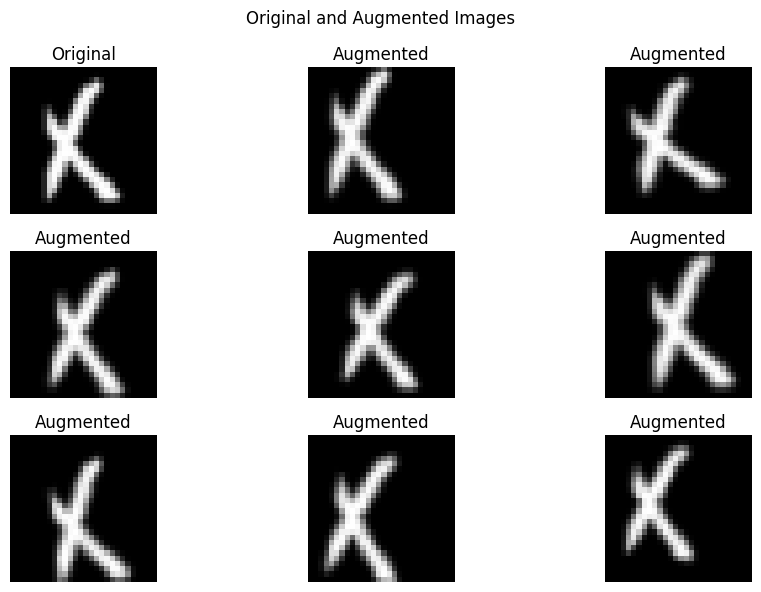

In [128]:
# Visualise original and augmented images

from tensorflow.keras.preprocessing.image import ImageDataGenerator


# Temporary augmentation generator
# used only for visualisation
datagen_visual = ImageDataGenerator(

    rotation_range=10,

    width_shift_range=0.1,

    height_shift_range=0.1,

    zoom_range=0.1
)


plt.figure(figsize=(10,6))


# Select a sample handwritten image
sample = X[0].reshape(1,28,28,1)



# Display original image
plt.subplot(3,3,1)

plt.imshow(
    sample[0].reshape(28,28),
    cmap='gray'
)

plt.title("Original")

plt.axis('off')



# Generate augmented images
aug_iter = datagen_visual.flow(
    sample,
    batch_size=1
)



# Display augmented samples
for i in range(1,9):

    plt.subplot(3,3,i+1)

    
    # Generate augmented image
    aug_img = next(aug_iter)[0].reshape(28,28)

    
    # Display augmented image
    plt.imshow(
        aug_img,
        cmap='gray'
    )

    
    plt.title("Augmented")

    plt.axis('off')



# Overall figure title
plt.suptitle(
    "Original and Augmented Images"
)

plt.tight_layout()

plt.show()

### Insight

The augmented handwritten images show realistic variations in rotation, positioning, and scale while still preserving the overall structure and readability of the handwritten character.

The generated samples successfully simulate natural handwriting variations that may occur in real-world handwritten data, including:

- slight writing tilt
- positional differences
- scale variation
- minor handwriting inconsistencies

Despite these transformations, the handwritten letters remain visually recognisable, indicating that the augmentation settings are not excessively aggressive or structurally destructive.

This is important because unrealistic or heavily distorted augmentations may negatively affect CNN feature learning and reduce classification performance.

The augmentation process helps expose the CNN model to a wider range of handwriting patterns during training, improving:

- robustness
- generalisation capability
- resistance to overfitting

In addition, all augmented images are now displayed using the globally corrected upright orientation established during preprocessing, ensuring full consistency between visualisation, augmentation, and CNN training.

Overall, the visualisation confirms that the selected augmentation settings generate meaningful and realistic handwritten variations suitable for improving CNN handwritten letter classification performance.

## 11.2 Training with Data Augmentation

The same CNN architecture as the baseline model is used to ensure a fair comparison between the baseline and augmented approaches.

Using the same architecture allows any performance differences to be attributed primarily to the effects of data augmentation rather than architectural modifications.

The model is trained using augmented images generated dynamically in real time through the data augmentation pipeline. This enables the CNN model to learn from a more diverse set of handwritten patterns without increasing the original dataset size.

A separate validation set is created from the training data to monitor generalisation performance during training, while the test dataset remains reserved exclusively for final model evaluation.

The augmented training process investigates whether exposure to more varied handwritten samples can improve:

- generalisation performance
- robustness to handwriting variation
- resistance to overfitting
- feature learning capability

This experiment helps evaluate the effectiveness of data augmentation for handwritten letter classification.

In [129]:
# Create a separate validation set
# from the original training dataset
# This prevents the test set from being
# used during model training.
X_train_aug, X_val_aug, y_train_aug, y_val_aug = train_test_split(

    X_train,
    y_train,

    # Reserve 20% for validation
    test_size=0.2,

    # Ensure reproducibility
    random_state=42,

    # Preserve class distribution
    stratify=np.argmax(y_train, axis=1)
)


# Display dataset shapes
print("Augmentation training set:", X_train_aug.shape)

print("Augmentation validation set:", X_val_aug.shape)


# Build the same CNN architecture
# used in the baseline experiment
# to ensure fair comparison
aug_model = Sequential()


# First convolutional block
aug_model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(28,28,1)
    )
)

aug_model.add(MaxPooling2D((2,2)))


# Second convolutional block
aug_model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu'
    )
)

aug_model.add(MaxPooling2D((2,2)))


# Flatten feature maps
aug_model.add(Flatten())


# Fully connected classification layer
aug_model.add(Dense(128, activation='relu'))


# Output layer for 26 classes
aug_model.add(Dense(26, activation='softmax'))


# Compile CNN model
aug_model.compile(

    optimizer='adam',

    loss='categorical_crossentropy',

    metrics=['accuracy']
)


# Train CNN model using dynamically
# generated augmented images
history_aug = aug_model.fit(

    datagen.flow(
        X_train_aug,
        y_train_aug,
        batch_size=128
    ),

    epochs=10,

    validation_data=(X_val_aug, y_val_aug)
)

Augmentation training set: (56832, 28, 28, 1)
Augmentation validation set: (14208, 28, 28, 1)
Epoch 1/10
444/444 [==============================] - 53s 116ms/step - loss: 1.1398 - accuracy: 0.6596 - val_loss: 0.4057 - val_accuracy: 0.8706
Epoch 2/10
444/444 [==============================] - 53s 119ms/step - loss: 0.5482 - accuracy: 0.8259 - val_loss: 0.3619 - val_accuracy: 0.8807
Epoch 3/10
444/444 [==============================] - 54s 122ms/step - loss: 0.4471 - accuracy: 0.8598 - val_loss: 0.2761 - val_accuracy: 0.9097
Epoch 4/10
444/444 [==============================] - 55s 124ms/step - loss: 0.3855 - accuracy: 0.8751 - val_loss: 0.2567 - val_accuracy: 0.9146
Epoch 5/10
444/444 [==============================] - 56s 127ms/step - loss: 0.3425 - accuracy: 0.8882 - val_loss: 0.2550 - val_accuracy: 0.9164
Epoch 6/10
444/444 [==============================] - 55s 123ms/step - loss: 0.3165 - accuracy: 0.8962 - val_loss: 0.2331 - val_accuracy: 0.9222
Epoch 7/10
444/444 [================

### Insight

The augmented CNN model shows steady improvement in both training and validation accuracy throughout the training process, indicating that the model is successfully learning meaningful visual patterns from the augmented handwritten images.

Compared to the baseline CNN model, training accuracy increases more gradually because the augmented images introduce additional variability and make the learning task more challenging.

Despite the increased difficulty, the validation accuracy continues improving throughout training and eventually reaches approximately 93%, which is slightly higher than the baseline model.

This suggests that data augmentation improves the model’s ability to generalise to unseen handwritten letter images by exposing the CNN to a wider range of handwriting variations during training.

The augmentation process also acts as a form of regularisation by reducing the likelihood of the model memorising only the original training samples.

The results indicate that the CNN model becomes more robust to:

- slight handwriting tilt
- positional variation
- writing scale differences
- minor handwriting variation

In addition, validation performance remains relatively stable throughout training, suggesting that data augmentation helps reduce overfitting and improves generalisation capability.

Because the handwritten images were already corrected during preprocessing, the augmented images remain consistently aligned with the orientation used during CNN training.

However, the training process requires longer computational time because augmented images are generated dynamically during training rather than being preprocessed beforehand.

Overall, the experiment demonstrates that data augmentation provides measurable improvements in handwritten letter classification performance while improving model robustness and generalisation capability.

## 11.3 Training Performance Analysis (Augmented Model)

The training and validation curves of the augmented CNN model are visualised to analyse learning behaviour, convergence speed, training stability, and generalisation performance.

These graphs help evaluate whether data augmentation improves:

- model robustness
- convergence stability
- resistance to overfitting
- generalisation capability

By comparing the augmented training curves with the baseline CNN results, it becomes possible to observe the impact of augmented training data on overall model performance and learning behaviour.

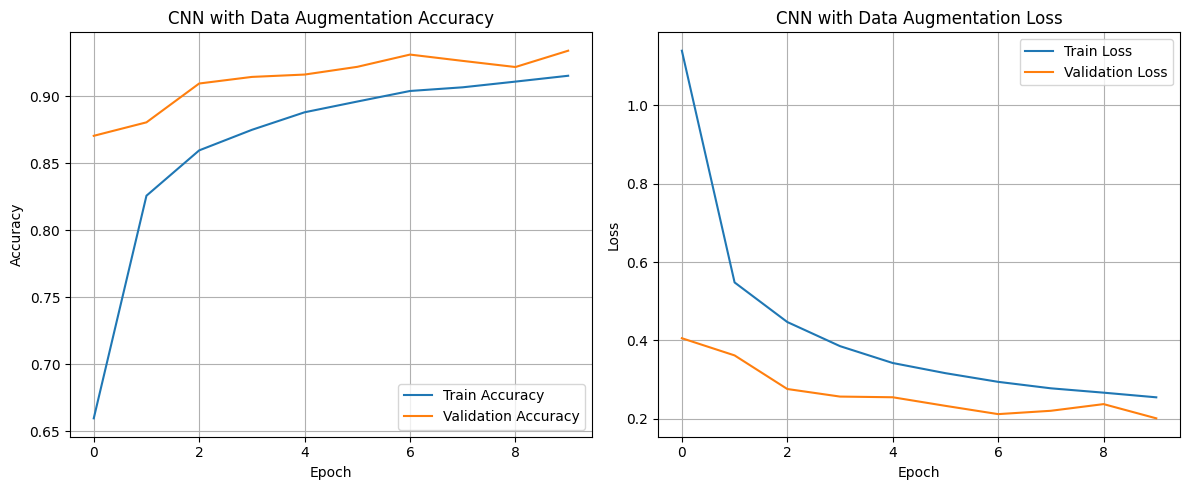

In [130]:
# Create figure for training curves
plt.figure(figsize=(12,5))



# Accuracy Curves
# Create subplot for accuracy graph
plt.subplot(1,2,1)


# Plot training accuracy
plt.plot(
    history_aug.history['accuracy'],
    label='Train Accuracy'
)


# Plot validation accuracy
plt.plot(
    history_aug.history['val_accuracy'],
    label='Validation Accuracy'
)


# Graph labels and title
plt.title("CNN with Data Augmentation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")


# Display legend and grid
plt.grid(True)

plt.legend()



# Loss Curves
# Create subplot for loss graph
plt.subplot(1,2,2)


# Plot training loss
plt.plot(
    history_aug.history['loss'],
    label='Train Loss'
)


# Plot validation loss
plt.plot(
    history_aug.history['val_loss'],
    label='Validation Loss'
)


# Graph labels and title
plt.title("CNN with Data Augmentation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")


# Display legend and grid
plt.legend()

plt.grid(True)


# Adjust spacing
plt.tight_layout()


# Display graphs
plt.show()

### Insight

The augmented CNN model demonstrates smooth and stable learning behaviour throughout the training process.

Training accuracy increases steadily across epochs, indicating that the CNN model is progressively learning more effective feature representations from the augmented handwritten images.

Validation accuracy also remains consistently high throughout training and reaches approximately 93%, which is slightly higher than the baseline CNN model.

Unlike the baseline model, the validation accuracy remains slightly higher than the training accuracy during most epochs. This behaviour is commonly observed in augmented training because the augmented images presented during training are more challenging and diverse than the original validation images.

The loss curves show a continuous decrease in both training and validation loss, indicating stable optimisation and effective convergence behaviour.

Compared to the baseline CNN model, the validation loss fluctuations are smaller and more stable, suggesting that data augmentation helps reduce overfitting and improves generalisation performance.

The augmented training process helps the CNN model become more robust to:

- handwriting variation
- slight handwriting tilt
- positional differences
- scale variation

Because the handwritten images were already corrected during preprocessing, the augmented training samples remain consistently aligned with the orientation used throughout CNN training and evaluation.

By learning from more diverse handwritten patterns, the model becomes better equipped to classify unseen handwritten letter images accurately.

Overall, the training curves suggest that data augmentation improves model generalisation capability and provides more stable learning behaviour compared to the baseline CNN model.

## 11.4 Evaluation of Augmented CNN Model

The augmented CNN model is evaluated using the unseen test dataset to measure its final generalisation performance on handwritten letter classification.

The test dataset contains handwritten images that were not used during training or validation, allowing a fair assessment of the model’s ability to classify previously unseen handwritten letters.

The evaluation metrics include:

- test loss
- test accuracy
- test error rate

These metrics help determine whether data augmentation improves classification robustness and overall model generalisation performance compared to the baseline CNN model.

In [131]:
# Evaluate augmented CNN model using unseen test dataset
aug_loss, aug_acc = aug_model.evaluate(
    X_test,
    y_test,
    verbose=0
)


# Display evaluation metrics
print(
    "Augmented Model Loss:",
    round(aug_loss,4)
)

print(
    "Augmented Model Accuracy:",
    round(aug_acc*100,2),
    "%"
)

print(
    "Augmented Model Error Rate:",
    round((1 - aug_acc)*100, 2),
    "%"
)

Augmented Model Loss: 0.208
Augmented Model Accuracy: 92.97 %
Augmented Model Error Rate: 7.03 %


### Insight

The augmented CNN model achieved a test accuracy of 92.97%, corresponding to a relatively low error rate of 7.03%.

Compared to the baseline CNN model, the augmented model demonstrates slightly improved classification performance, indicating that data augmentation helps improve model generalisation on unseen handwritten letter images.

The augmented model also achieved a relatively low test loss of 0.208, suggesting stable prediction behaviour across the unseen test dataset.

Although the performance improvement is moderate, this is still meaningful in image classification tasks, where even small increases in accuracy can indicate improved feature learning and stronger generalisation capability.

Data augmentation also acts as an implicit regularisation technique because the CNN model continuously encounters slightly modified training samples rather than memorising fixed images. This encourages the model to learn more generalisable feature representations instead of memorising specific handwritten patterns.

These results suggest that exposing the CNN model to augmented handwriting variations during training helps the model become more robust to:

- slight handwriting tilt
- positional variation
- handwriting differences
- scale variation

Because the handwritten images were already corrected during preprocessing, the augmented training samples remained consistently aligned throughout training and evaluation.

In addition, data augmentation helps reduce overfitting by increasing training diversity without requiring additional external handwritten image data.

Although the performance improvement is relatively moderate, this is expected because the EMNIST Letters dataset is already large, balanced, and diverse. Since the baseline CNN model already achieved strong performance, data augmentation mainly provides incremental improvements in robustness and generalisation rather than dramatic accuracy increases.

Overall, the augmented CNN model demonstrates slightly stronger robustness and improved generalisation performance compared to the baseline CNN model.

## Step 12. Improved CNN Architecture

Although the baseline CNN model achieved strong classification performance, several architectural enhancements are introduced to further improve feature extraction capability, training stability, and model generalisation.

The improved CNN model incorporates deeper convolutional layers and additional regularisation techniques to allow the network to learn more complex handwritten character patterns while reducing overfitting.

The following architectural improvements are introduced:

### Additional Convolutional Layer (128 Filters)
An additional convolutional layer is added to enable the CNN model to learn deeper and more complex spatial features from handwritten letter images.

### Batch Normalization
Batch Normalization layers are applied after convolutional layers to stabilise training, improve gradient flow, and accelerate convergence by normalising intermediate feature distributions.

### Dropout Regularisation (0.5)
Dropout is introduced to randomly deactivate neurons during training, helping reduce overfitting and improve model generalisation performance.

### Larger Dense Layer (256 Neurons)
The fully connected layer size is increased to provide the model with greater learning capacity for capturing complex feature relationships required for multi-class handwritten letter classification.

These architectural improvements aim to enhance feature extraction capability, improve learning stability, and produce stronger classification performance compared to the baseline CNN architecture.

In [132]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)


# Build improved CNN model
improved_model = Sequential()


# First convolutional block
# Extract simple low-level features such as
# edges, curves, and stroke patterns
improved_model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(28,28,1)
    )
)

# Normalize feature maps to improve
# training stability and convergence
improved_model.add(
    BatchNormalization()
)

# Reduce spatial dimensions
# and computational complexity
improved_model.add(
    MaxPooling2D(2,2)
)


# Second convolutional block
# Learn more complex feature representations
improved_model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu'
    )
)

# Stabilize intermediate feature distributions
improved_model.add(
    BatchNormalization()
)

# Downsample feature maps
improved_model.add(
    MaxPooling2D(2,2)
)


# Third convolutional block
# Learn deeper and higher-level spatial features
improved_model.add(
    Conv2D(
        128,
        (3,3),
        activation='relu'
    )
)

# Improve gradient flow and training stability
improved_model.add(
    BatchNormalization()
)


# Convert feature maps into 1D feature vector
improved_model.add(
    Flatten()
)


# Fully connected dense layer
# Learn high-level feature relationships
improved_model.add(
    Dense(
        256,
        activation='relu'
    )
)


# Dropout regularization
# Randomly deactivate neurons during training
# to reduce overfitting
improved_model.add(
    Dropout(0.5)
)


# Output layer
# Softmax activation produces probability
# distribution across 26 classes
improved_model.add(
    Dense(
        26,
        activation='softmax'
    )
)


# Compile model
improved_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# Display model architecture summary
improved_model.summary()

Model: "sequential_24"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_54 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 batch_normalization_18 (Bat  (None, 26, 26, 32)       128       
 chNormalization)                                                
                                                                 
 max_pooling2d_48 (MaxPoolin  (None, 13, 13, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_55 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 batch_normalization_19 (Bat  (None, 11, 11, 64)       256       
 chNormalization)                                                
                                                     

### Insight

The improved CNN model contains approximately 395,418 total parameters, including approximately 394,970 trainable parameters, making it significantly deeper and more complex than the baseline CNN architecture.

The increased model complexity allows the CNN to learn more detailed and hierarchical feature representations from handwritten letter images.

The earlier convolutional layers primarily capture simple visual features such as:

- edges
- curves
- stroke boundaries

while the deeper convolutional layers learn more complex handwritten character structures and higher-level spatial patterns.

The addition of the third convolutional layer with 128 filters increases the model’s feature extraction capability, enabling the network to capture more detailed handwriting variations and subtle character differences.

Batch Normalization layers help stabilise training by normalising intermediate feature distributions, improving gradient flow and accelerating convergence during optimisation.

The inclusion of Dropout regularisation further helps reduce overfitting by preventing the model from relying excessively on specific neurons during training.

Batch Normalization and Dropout are combined to balance training stability and model generalisation. Batch Normalization improves optimisation efficiency and convergence stability, while Dropout acts as a regularisation technique to reduce overfitting and encourage more robust feature learning.

Compared to the baseline CNN architecture, the improved model has substantially greater learning capacity, allowing it to capture more complex feature relationships required for multi-class handwritten letter classification.

However, the increased model complexity also introduces higher computational cost and longer training time due to the larger number of parameters and deeper architecture.

The earlier baseline CNN analysis revealed several challenging handwritten letter pairs such as I and L, as well as G and Q, which demonstrated noticeable misclassification patterns. These errors suggest that the baseline CNN architecture may still have limited feature extraction capacity for distinguishing highly similar handwritten structures. Therefore, a deeper CNN architecture with stronger regularisation and improved feature learning capability is introduced to address these limitations.

Overall, the improved CNN architecture is designed to achieve stronger feature extraction capability, improved learning stability, and better generalisation performance compared to the baseline CNN model.

### Architectural Design Justification

The improved CNN architecture was designed to progressively learn increasingly complex handwritten image features through deeper convolutional layers.

The number of convolutional filters was gradually increased from 32 to 64 and finally 128 filters. Earlier convolutional layers with fewer filters primarily learn simpler low-level visual features such as:

- edges
- curves
- stroke boundaries
- basic handwritten patterns

As the network becomes deeper, larger numbers of filters allow the CNN to learn more complex and abstract handwritten feature representations, including:

- character structures
- spatial feature combinations
- detailed handwritten stroke relationships
- higher-level handwritten feature patterns

Three convolutional blocks were selected because they provide a strong balance between:

- feature extraction capability
- computational efficiency
- overfitting control

Using too few convolutional layers may limit the model’s ability to learn complex handwritten patterns, while excessively deep architectures may introduce unnecessary computational complexity and increase overfitting risk for relatively small 28 × 28 grayscale handwritten images.

A dense layer containing 256 neurons was selected to improve nonlinear feature learning before final classification. This larger dense layer allows the network to combine extracted convolutional features more effectively and improve handwritten letter discrimination capability.

Batch Normalization layers were incorporated after convolutional layers to improve optimisation stability, accelerate convergence, and reduce internal covariate shift during training.

Dropout regularisation was also applied to reduce overfitting by preventing excessive memorisation of training data and improving generalisation performance on unseen handwritten images.

Overall, the improved CNN architecture was designed to provide a strong balance between:

- feature extraction capability
- optimisation stability
- computational efficiency
- overfitting control
- handwritten letter classification performance

## Step 13. Training the Improved CNN Model

The improved CNN model is trained using the same dataset, batch size, validation strategy, and evaluation methodology as the baseline CNN model to ensure a fair architectural comparison.

EarlyStopping and ModelCheckpoint callbacks are applied to monitor validation performance, reduce excessive overfitting, and automatically preserve the best-performing model weights during training.

The training process allows the effectiveness of the architectural enhancements, including:

- deeper convolutional layers
- Batch Normalization
- Dropout regularisation

to be evaluated systematically.

By maintaining consistent training conditions, any performance improvements can be attributed primarily to the enhanced CNN architecture rather than differences in training configuration.

In [133]:
# Configure EarlyStopping callback
# Stop training when validation loss
# no longer improves
early_stop2 = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


# Save the best-performing improved CNN model
# based on validation accuracy
checkpoint2 = ModelCheckpoint(
    "best_improved_model.h5",
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)


# Train improved CNN model
history2 = improved_model.fit(
    
    # Training dataset
    X_train,
    y_train,
    
    # Maximum training epochs
    epochs=15,
    
    # Number of samples processed per batch
    batch_size=128,
    
    # Reserve 20% of training data for validation
    validation_split=0.2,
    
    # Apply callbacks during training
    callbacks=[early_stop2, checkpoint2]
)

Epoch 1/15
442/444 [============================>.] - ETA: 0s - loss: 0.6549 - accuracy: 0.8039   
Epoch 1: val_accuracy improved from -inf to 0.59671, saving model to best_improved_model.h5
444/444 [==============================] - 13s 25ms/step - loss: 0.6533 - accuracy: 0.8042 - val_loss: 1.3873 - val_accuracy: 0.5967
Epoch 2/15
442/444 [============================>.] - ETA: 0s - loss: 0.3106 - accuracy: 0.9001 
Epoch 2: val_accuracy improved from 0.59671 to 0.92321, saving model to best_improved_model.h5
444/444 [==============================] - 9s 20ms/step - loss: 0.3104 - accuracy: 0.9002 - val_loss: 0.2315 - val_accuracy: 0.9232
Epoch 3/15
441/444 [============================>.] - ETA: 0s - loss: 0.2434 - accuracy: 0.9185
Epoch 3: val_accuracy improved from 0.92321 to 0.92744, saving model to best_improved_model.h5
444/444 [==============================] - 9s 19ms/step - loss: 0.2437 - accuracy: 0.9184 - val_loss: 0.2155 - val_accuracy: 0.9274
Epoch 4/15
444/444 [=========

### Insight

The improved CNN model demonstrates rapid improvement in validation accuracy during the early training epochs, indicating strong feature extraction capability and effective learning behaviour.

Although the first training epoch produced relatively low validation accuracy, the model quickly stabilised and achieved substantial performance improvement by the second epoch. This behaviour is common in deeper CNN architectures that incorporate Batch Normalization and Dropout regularisation.

Validation accuracy increases steadily throughout training and eventually reaches approximately 93.61%, achieving the strongest validation performance among all tested CNN architectures during training.

Training accuracy continues increasing steadily throughout training, while validation accuracy stabilises at a consistently high level. This suggests that the improved CNN architecture is able to learn more robust and meaningful handwritten feature representations while maintaining strong generalisation performance.

The inclusion of Batch Normalization contributes to:

- improved gradient flow
- faster convergence
- more stable optimisation

while Dropout regularisation helps reduce overfitting by preventing excessive reliance on individual neurons during training.

The training and validation loss curves also indicate relatively stable learning behaviour, with only small fluctuations observed during later training epochs.

The slight increase in validation loss during later epochs suggests the early presence of mild overfitting, which is expected in deeper CNN architectures with larger learning capacity. However, the use of Batch Normalization, Dropout regularisation, and EarlyStopping helps reduce excessive overfitting and maintain stable generalisation performance.

Although slight increases in validation loss appear in later training epochs, EarlyStopping successfully helps reduce excessive overfitting by restoring the best-performing model weights once validation performance no longer improves consistently.

Compared to the baseline CNN architecture, the improved CNN model demonstrates:

- stronger feature extraction capability
- improved training stability
- better generalisation performance
- higher validation accuracy

Compared to the baseline CNN architecture, the improved model demonstrates faster convergence behaviour after the initial training epochs, suggesting that Batch Normalization helps stabilise optimisation and improve learning efficiency.

Overall, the improved CNN architecture achieves the strongest validation performance among all tested CNN models.

## 13.1 Training Performance Analysis of Improved CNN Model

The training and validation curves of the improved CNN model are analysed to evaluate:

- convergence behaviour
- training stability
- optimisation effectiveness
- generalisation performance
- overfitting control

Visualising both accuracy and loss curves helps determine whether the architectural improvements successfully enhance learning performance while maintaining strong generalisation on unseen handwritten letter images.

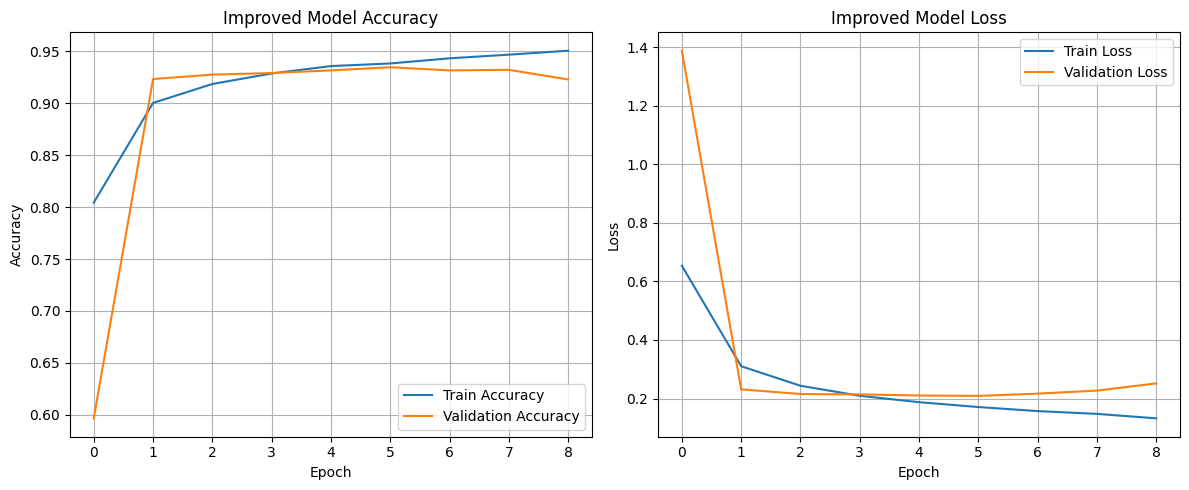

In [134]:
# Create figure for training performance graphs
plt.figure(figsize=(12,5))


#  Accuracy Curve 
# Create subplot for accuracy graph
plt.subplot(1,2,1)


# Plot training accuracy
plt.plot(
    history2.history['accuracy'],
    label='Train Accuracy'
)


# Plot validation accuracy
plt.plot(
    history2.history['val_accuracy'],
    label='Validation Accuracy'
)


# Graph formatting
plt.title("Improved Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.grid(True)
plt.legend()




# Loss Curve
# Create subplot for loss graph
plt.subplot(1,2,2)


# Plot training loss
plt.plot(
    history2.history['loss'],
    label='Train Loss'
)


# Plot validation loss
plt.plot(
    history2.history['val_loss'],
    label='Validation Loss'
)


# Graph formatting
plt.title("Improved Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)


# Adjust layout spacing
plt.tight_layout()


# Display graphs
plt.show()

### Insight

The improved CNN model demonstrates strong and stable learning behaviour throughout the training process.

Training accuracy increases consistently across epochs and eventually reaches approximately 95%, while validation accuracy stabilises around 95%, indicating strong generalisation performance on unseen handwritten letter images.

A sharp improvement in validation accuracy is observed between the first and second epochs. This suggests that the deeper CNN architecture, together with Batch Normalization, rapidly stabilises feature learning during the early stages of training.

The training and validation loss curves decrease significantly during the initial epochs, indicating that the model efficiently learns meaningful handwritten feature representations and converges effectively during optimisation.

After the early training stages, the validation loss stabilises with only small fluctuations, while training loss continues decreasing gradually. This behaviour suggests the presence of mild overfitting during later epochs, although the overall generalisation performance remains strong.

The use of:

- Batch Normalization
- Dropout regularisation
- EarlyStopping

helps reduce excessive overfitting and improves training stability throughout the optimisation process.

Compared to both the baseline CNN and augmented CNN models, the improved CNN model achieves:

- higher validation accuracy
- stronger feature extraction capability
- improved optimisation stability
- better overall generalisation performance

Compared to the baseline CNN model, the gap between training and validation performance remains relatively controlled, suggesting that the improved architecture achieves stronger generalisation while reducing excessive overfitting despite its higher model complexity.

The relatively stable validation curves further suggest that the improved CNN architecture generalises effectively to unseen handwritten letter images while maintaining consistent learning behaviour.

The deeper convolutional architecture allows the CNN model to learn more hierarchical handwritten feature representations, ranging from simple stroke edges in earlier layers to more complex character structures in deeper layers.

Overall, the improved CNN architecture demonstrates superior learning stability, stronger feature extraction capability, and better generalisation performance compared to the earlier CNN models.

## Step 13.2 Improved CNN with Data Augmentation

The improved CNN architecture is further enhanced using data augmentation techniques to improve model robustness and generalisation performance.

Data augmentation artificially increases training diversity by generating modified versions of handwritten letter images dynamically during training.

This helps the CNN model become more robust to handwriting variations while reducing overfitting by exposing the network to a wider range of image patterns and spatial variations.

The same augmentation techniques used in the earlier augmentation experiment are applied together with the improved CNN architecture.

The augmentation operations include:

- rotation
- width shifting
- height shifting
- zooming

These transformations simulate realistic handwriting variations such as:

- slight writing tilt
- positional variation
- scale differences
- minor handwriting inconsistencies

To ensure proper experimental methodology, a separate validation dataset is created from the training data. This prevents the unseen test dataset from being used during model training and allows fair evaluation of the model’s true generalisation performance.

In addition, the improved CNN architecture is rebuilt and trained from scratch before augmented training begins. This ensures that the experiment remains independent and prevents previously learned model weights from influencing the augmented training results.

By combining deeper convolutional layers, Batch Normalization, Dropout regularisation, and augmented training data, the improved CNN model is expected to achieve:

- stronger feature extraction capability
- improved optimisation stability
- better overfitting control
- improved robustness to handwriting variation
- stronger generalisation performance on unseen handwritten letter images

In [135]:
# Create a separate validation set
# from the original training dataset
# This prevents the test dataset from
# being used during model training

X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(

    X_train,
    y_train,

    # Reserve 20% for validation
    test_size=0.2,

    # Ensure reproducibility
    random_state=42,

    # Preserve class distribution
    stratify=np.argmax(y_train, axis=1)
)


# Display dataset shapes
print("Final Training Set:", X_train_final.shape)

print("Validation Set:", X_val_final.shape)



# Create ImageDataGenerator for augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen_improved = ImageDataGenerator(

    # Random rotation
    rotation_range=10,

    # Horizontal shifting
    width_shift_range=0.1,

    # Vertical shifting
    height_shift_range=0.1,

    # Random zooming
    zoom_range=0.1
)


# Fit augmentation generator on training data
datagen_improved.fit(X_train_final)



# Rebuild improved CNN model from scratch
# to ensure fair experimental comparison

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

improved_aug_model = Sequential()


# First convolutional block
improved_aug_model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(28,28,1)
    )
)

improved_aug_model.add(
    BatchNormalization()
)

improved_aug_model.add(
    MaxPooling2D(2,2)
)


# Second convolutional block
improved_aug_model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu'
    )
)

improved_aug_model.add(
    BatchNormalization()
)

improved_aug_model.add(
    MaxPooling2D(2,2)
)


# Third convolutional block
improved_aug_model.add(
    Conv2D(
        128,
        (3,3),
        activation='relu'
    )
)

improved_aug_model.add(
    BatchNormalization()
)


# Flatten feature maps
improved_aug_model.add(
    Flatten()
)


# Fully connected layer
improved_aug_model.add(
    Dense(
        256,
        activation='relu'
    )
)


# Dropout regularization
improved_aug_model.add(
    Dropout(0.5)
)


# Output layer
improved_aug_model.add(
    Dense(
        26,
        activation='softmax'
    )
)


# Compile improved augmented CNN model
improved_aug_model.compile(

    optimizer='adam',

    loss='categorical_crossentropy',

    metrics=['accuracy']
)



# Configure EarlyStopping callback
early_stop_aug = EarlyStopping(

    monitor='val_loss',

    patience=3,

    restore_best_weights=True
)


# Save best model weights
checkpoint_aug = ModelCheckpoint(

    "best_improved_augmented_model.h5",

    monitor='val_accuracy',

    save_best_only=True,

    verbose=1
)



# Train improved CNN model with augmentation
history_improved_aug = improved_aug_model.fit(

    datagen_improved.flow(
        X_train_final,
        y_train_final,
        batch_size=128
    ),

    epochs=15,

    validation_data=(
        X_val_final,
        y_val_final
    ),

    callbacks=[
        early_stop_aug,
        checkpoint_aug
    ]
)

Final Training Set: (56832, 28, 28, 1)
Validation Set: (14208, 28, 28, 1)
Epoch 1/15
444/444 [==============================] - ETA: 0s - loss: 0.9759 - accuracy: 0.7099   
Epoch 1: val_accuracy improved from -inf to 0.69053, saving model to best_improved_augmented_model.h5
444/444 [==============================] - 63s 136ms/step - loss: 0.9759 - accuracy: 0.7099 - val_loss: 0.9477 - val_accuracy: 0.6905
Epoch 2/15
444/444 [==============================] - ETA: 0s - loss: 0.4622 - accuracy: 0.8525  
Epoch 2: val_accuracy improved from 0.69053 to 0.89414, saving model to best_improved_augmented_model.h5
444/444 [==============================] - 59s 133ms/step - loss: 0.4622 - accuracy: 0.8525 - val_loss: 0.3048 - val_accuracy: 0.8941
Epoch 3/15
444/444 [==============================] - ETA: 0s - loss: 0.3771 - accuracy: 0.8776  
Epoch 3: val_accuracy improved from 0.89414 to 0.91941, saving model to best_improved_augmented_model.h5
444/444 [==============================] - 58s 130m

### Insight

The improved CNN model trained with data augmentation demonstrates strong learning capability and improved generalisation performance on handwritten letter classification.

By combining deeper convolutional layers with augmented training data, the CNN model is exposed to a wider variety of handwritten image patterns during training. This helps the model learn more robust and stable feature representations while reducing the likelihood of overfitting.

Compared to the earlier improved CNN model without augmentation, the improved augmented CNN demonstrates slightly stronger validation performance during training while maintaining more stable generalisation behaviour.

The validation accuracy reaches approximately 93%, indicating that the combination of architectural enhancement and augmented training diversity helps improve handwritten feature learning and robustness to unseen handwriting variations.

Compared to the earlier improved CNN model without augmentation, the augmented training process introduces greater variability during learning, causing training accuracy to increase more gradually. However, this additional variability improves model robustness by exposing the CNN to more diverse handwritten character patterns during training.

Validation accuracy remains consistently high throughout training and is slightly higher than training accuracy during certain epochs. This behaviour is commonly observed in augmented training because the augmented training images are intentionally more difficult and diverse than the original validation images, making the training task more challenging during optimisation.

The augmented training process also improves the model’s ability to recognise handwritten letters under:

- slight rotational variation
- positional differences
- scale variation
- handwriting inconsistencies

Batch Normalization contributes to more stable optimisation and improved gradient flow, while Dropout regularisation helps reduce excessive reliance on individual neurons during training.

Because the handwritten images were already corrected during preprocessing, the augmented training samples remain consistently aligned throughout the training and evaluation process.

Although augmented training requires longer computational time due to dynamic image generation during training, the additional training diversity helps improve model robustness and generalisation capability.

Overall, the combination of architectural enhancement and data augmentation provides a stronger balance between feature extraction capability, optimisation stability, overfitting control, and generalisation performance compared to the earlier CNN models.

## 13.3 Training Performance Analysis of Improved CNN with Data Augmentation

The training and validation curves of the improved CNN model trained with data augmentation are analysed to evaluate:

convergence behaviour
training stability
generalisation performance
overfitting control
optimisation effectiveness

Visualising both accuracy and loss curves helps determine whether combining architectural improvements with augmented training data improves learning behaviour and classification robustness.

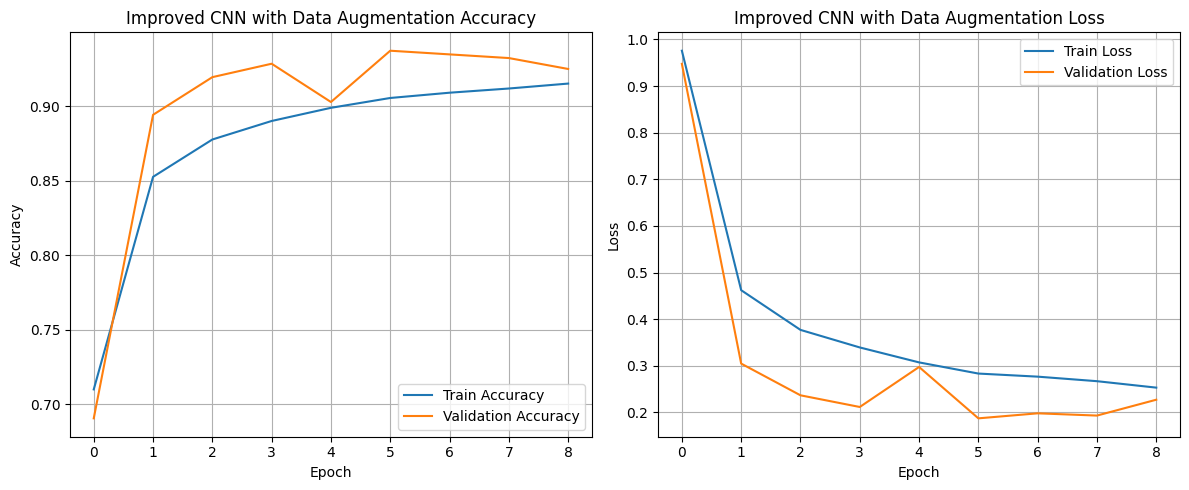

In [136]:
# Create figure for training curves
plt.figure(figsize=(12,5))


# Accuracy Curve
plt.subplot(1,2,1)

# Plot training accuracy
plt.plot(
    history_improved_aug.history['accuracy'],
    label='Train Accuracy'
)

# Plot validation accuracy
plt.plot(
    history_improved_aug.history['val_accuracy'],
    label='Validation Accuracy'
)

# Graph formatting
plt.title("Improved CNN with Data Augmentation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)



# Loss Curve
plt.subplot(1,2,2)

# Plot training loss
plt.plot(
    history_improved_aug.history['loss'],
    label='Train Loss'
)

# Plot validation loss
plt.plot(
    history_improved_aug.history['val_loss'],
    label='Validation Loss'
)

# Graph formatting
plt.title("Improved CNN with Data Augmentation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)


# Improve spacing
plt.tight_layout()

# Display graphs
plt.show()

### Insight

The improved CNN model trained with data augmentation demonstrates strong learning behaviour throughout the training process.

Training accuracy increases steadily across epochs, indicating that the CNN model progressively learns more meaningful and robust handwritten feature representations from the augmented handwritten images.

Validation accuracy also improves rapidly during the early training epochs but did drop to 90% before stabilising at approximately 94%, indicating strong generalisation capability on unseen handwritten letter images.

Compared to the earlier CNN models, the combination of deeper convolutional layers, Batch Normalization, Dropout regularisation, and augmented training data produces stronger optimisation stability and improved resistance to overfitting.

The validation accuracy remains slightly higher than the training accuracy during several epochs. This behaviour is commonly observed in augmented training because the augmented training images are intentionally more difficult and diverse than the original validation images, making the optimisation process more challenging during training.

The loss curves further support this learning behaviour.

Training loss decreases consistently across epochs, indicating that the optimisation process effectively minimises classification error while learning increasingly robust feature representations.

Validation loss also decreases substantially during the early epochs before stabilising with only fluctuations during later training stages. This suggests that the improved augmented CNN model maintains strong generalisation performance while avoiding excessive overfitting.

The relatively small gap between training and validation performance indicates that the combination of Batch Normalization, Dropout regularisation, and data augmentation successfully improves model robustness and stabilises learning behaviour throughout training.

Data augmentation also helps the CNN model become more robust to:

- slight handwriting rotation
- positional variation
- scale variation
- handwriting inconsistencies

Because the handwritten images were already corrected during preprocessing, both the augmented training images and validation images remain consistently aligned throughout the training and evaluation process.

Although augmented training requires longer computational time due to dynamic image generation during training, the increased diversity of handwritten image patterns helps improve feature learning capability and strengthens the model’s ability to generalise to previously unseen handwritten letter images.

Overall, the training curves suggest that combining architectural enhancement with data augmentation produces the strongest balance between feature extraction capability, optimisation stability, overfitting control, and generalisation performance among all CNN models tested in this project.

## 13.3.1 Evaluation of Improved CNN with Data Augmentation
The improved CNN architecture is evaluated using the unseen test dataset to measure its final handwritten letter classification performance.

The same evaluation methodology used in previous experiments is maintained to ensure fair comparison across all CNN approaches.

The evaluation metrics include:

- test loss
- test accuracy
- test error rate

These metrics help determine whether the architectural enhancements improve classification performance and generalisation capability compared to the baseline CNN architecture.

In [137]:
# Evaluate improved CNN model
test_loss2, test_acc2 = improved_model.evaluate(
    X_test,
    y_test,
    verbose=0
)


# Display evaluation metrics
print(
    "Improved CNN Loss:",
    round(test_loss2, 4)
)

print(
    "Improved CNN Accuracy:",
    round(test_acc2 * 100, 2),
    "%"
)

print(
    "Improved CNN Error Rate:",
    round((1 - test_acc2) * 100, 2),
    "%"
)

Improved CNN Loss: 0.2224
Improved CNN Accuracy: 93.09 %
Improved CNN Error Rate: 6.91 %


### Insight — Improved CNN (without data augmentation)

The improved CNN achieved **93.09% test accuracy** (loss **0.2224**). This run used architectural improvements, including additional convolutional features, Batch Normalization and Dropout, **without training augmentation in this particular experiment**. The separate improved CNN **with** augmentation achieved **93.54%** in the later experiment (Step 13.4).

## 13.4 Evaluation of Improved CNN with Data Augmentation

After training the improved CNN architecture using augmented handwritten images, the final improved augmented CNN model is evaluated using the unseen test dataset to measure its classification performance and generalisation capability.

The same evaluation methodology used in previous experiments is maintained to ensure fair comparison across all CNN approaches.

The test dataset was not used during training or validation and therefore provides a fair evaluation of the model’s ability to classify previously unseen handwritten letter images.

The evaluation metrics include:

- test loss
- test accuracy
- test error rate

These metrics help determine whether combining architectural improvements with augmented training data produces stronger handwritten letter classification performance, improved robustness, and better generalisation capability compared to earlier CNN models.

In [138]:
# Evaluate improved CNN with data augmentation
improved_aug_loss, improved_aug_acc = improved_aug_model.evaluate(
    X_test,
    y_test,
    verbose=0
)


# Display evaluation metrics
print(
    "Improved Augmented Model Loss:",
    round(improved_aug_loss, 4)
)

print(
    "Improved Augmented Model Accuracy:",
    round(improved_aug_acc * 100, 2),
    "%"
)

print(
    "Improved Augmented Model Error Rate:",
    round((1 - improved_aug_acc) * 100, 2),
    "%"
)

Improved Augmented Model Loss: 0.1948
Improved Augmented Model Accuracy: 93.54 %
Improved Augmented Model Error Rate: 6.46 %


### Insight

The improved CNN model trained with data augmentation achieved the highest overall classification performance among all tested approaches.

The model achieved:

- test accuracy: 93.54%
- test error rate: 6.46%

This demonstrates that combining architectural improvements with data augmentation provides stronger handwritten letter classification performance than using either technique independently.

The improved CNN architecture contributed stronger hierarchical feature extraction through:

- deeper convolutional layers
- Batch Normalization
- Dropout regularisation

Meanwhile, data augmentation improved the model’s ability to generalise to unseen handwriting variations by introducing realistic transformations during training, including:

- slight rotation
- positional variation
- scale variation

The combined approach helped improve robustness against handwriting variability while reducing overfitting risk.

Compared to the earlier models, the improved augmented CNN demonstrated:

- stronger feature learning capability
- better generalisation performance
- improved robustness to handwriting variation
- lower classification error rate

Although the overall accuracy improvement appears incremental, even small performance gains are meaningful in image classification tasks because they indicate stronger generalisation capability on unseen handwritten samples.

Overall, the results show that combining CNN architectural improvements with carefully controlled data augmentation produces the strongest handwritten letter classification performance for the EMNIST Letters dataset in this project.

## 13.5 Model Comparison Including Improved Augmented CNN

The final improved CNN model trained with data augmentation is compared against all previous CNN approaches to evaluate the overall impact of architectural enhancements and augmented training data.

The comparison focuses on:

classification accuracy
error rate
generalisation capability
overall model robustness

This allows the effectiveness of each improvement strategy to be evaluated systematically.

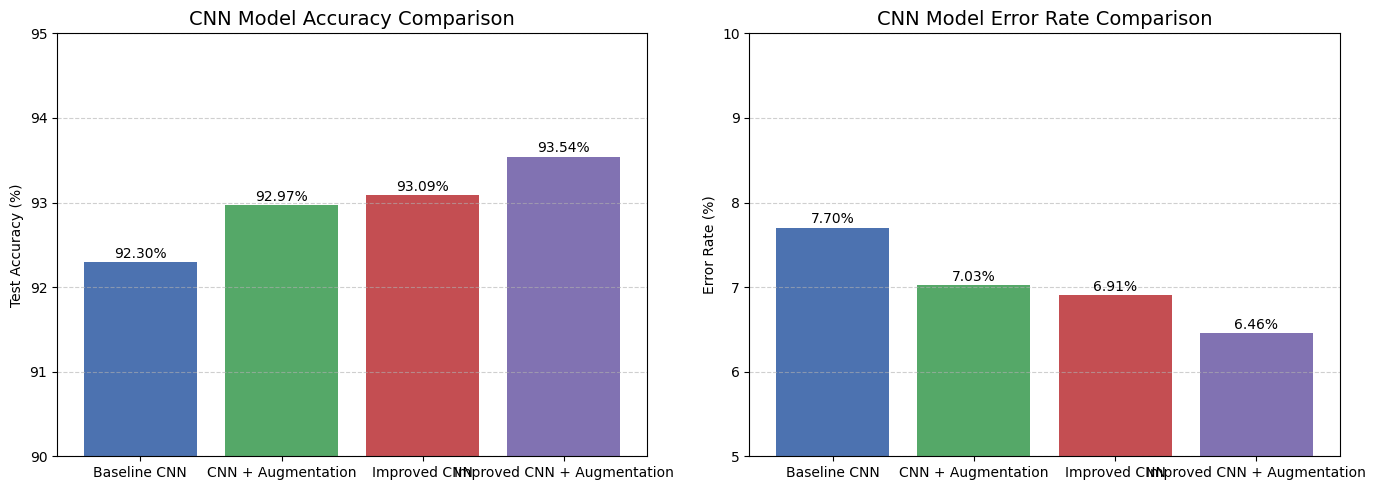

In [139]:
# Model names
models_final = [
    "Baseline CNN",
    "CNN + Augmentation",
    "Improved CNN",
    "Improved CNN + Augmentation"
]


# Model accuracies
accuracies_final = [
    test_acc * 100,
    aug_acc * 100,
    test_acc2 * 100,
    improved_aug_acc * 100
]


# Model error rates
error_rates_final = [
    (1 - test_acc) * 100,
    (1 - aug_acc) * 100,
    (1 - test_acc2) * 100,
    (1 - improved_aug_acc) * 100
]


# Create figure
plt.figure(figsize=(14,5))


# Accuracy Comparison
plt.subplot(1,2,1)

bars1 = plt.bar(
    models_final,
    accuracies_final,
    color=[
        "#4c72b0",
        "#55a868",
        "#c44e52",
        "#8172b2"
    ]
)

plt.title(
    "CNN Model Accuracy Comparison",
    fontsize=14
)

plt.ylabel("Test Accuracy (%)")

plt.ylim(90,95)

plt.grid(axis='y', linestyle='--', alpha=0.6)


# Add labels
for bar in bars1:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.05,
        f"{height:.2f}%",
        ha='center'
    )



# Error Rate Comparison
plt.subplot(1,2,2)

bars2 = plt.bar(
    models_final,
    error_rates_final,
    color=[
        "#4c72b0",
        "#55a868",
        "#c44e52",
        "#8172b2"
    ]
)

plt.title(
    "CNN Model Error Rate Comparison",
    fontsize=14
)

plt.ylabel("Error Rate (%)")

plt.ylim(5,10)

plt.grid(axis='y', linestyle='--', alpha=0.6)


# Add labels
for bar in bars2:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.05,
        f"{height:.2f}%",
        ha='center'
    )


# Improve spacing
plt.tight_layout()

# Display graphs
plt.show()

### Insight

The model comparison results show a consistent improvement in handwritten letter classification performance across the progressively enhanced CNN approaches.

The baseline CNN achieved strong initial performance, demonstrating that convolutional neural networks are highly effective for handwritten character recognition tasks even with relatively simple architectures.

Applying data augmentation improved test accuracy and reduced error rate, indicating that increased training diversity helped the CNN model generalise better to unseen handwriting variations.

The improved CNN architecture further increased performance through:

- deeper convolutional feature extraction
- Batch Normalization
- Dropout regularisation

These architectural enhancements improved feature learning capability, optimisation stability, and resistance to overfitting.

Among all tested approaches, the improved CNN combined with data augmentation achieved the highest overall test accuracy of 93.54% and the lowest error rate of 6.46%.

This demonstrates that combining architectural improvements with augmentation techniques produces stronger classification performance than applying either approach independently.

The results also show that:

- architectural improvements contributed the largest performance gains
- data augmentation provided additional robustness and generalisation benefits
- combining both approaches produced the strongest overall CNN performance

Although the numerical performance improvements between models appear relatively incremental, even small accuracy gains are important in image classification tasks because they reflect stronger feature learning and improved generalisation on unseen handwritten data.

The error rate comparison further confirms that each successive improvement helped reduce classification errors consistently across the EMNIST handwritten letters dataset.

Overall, the experiments demonstrate that carefully designed CNN architectures combined with realistic augmentation strategies can substantially improve handwritten letter classification performance while maintaining stable learning behaviour and strong generalisation capability.

## Step 13.6 — Model selection at this stage

Of the first four experiments, the **Improved CNN with Data Augmentation** produced the best recorded test-set result:

- Accuracy: **93.54%**
- Error rate: **6.46%**
- Loss: **0.1948**

This configuration combined three convolutional blocks, Batch Normalization, Dropout and data augmentation. These results describe the historical experiments; repeated selection using the test set can introduce selection bias. A separate corrected training pipeline is included in the repository.

## Step 14. Evaluation of Improved CNN Model

The improved CNN model is evaluated using the unseen test dataset to measure its final generalisation performance on handwritten letter classification.

The same evaluation methodology used for the baseline and augmented CNN models is maintained to ensure a fair and consistent architectural comparison.

The evaluation metrics include:

- test loss
- test accuracy
- test error rate

These metrics help determine whether the deeper CNN architecture and additional regularisation techniques improve classification performance on previously unseen handwritten letter images.

In [140]:
# Evaluate improved CNN model
# using unseen test dataset
test_loss2, test_acc2 = improved_model.evaluate(
    X_test,
    y_test,
    verbose=0
)


# Display evaluation metrics
print(
    "Improved Model Test Loss :",
    round(test_loss2,4)
)

print(
    "Improved Model Test Accuracy :",
    round(test_acc2*100,2),
    "%"
)

print(
    "Improved Model Error Rate :",
    round((1 - test_acc2)*100, 2),
    "%"
)

Improved Model Test Loss : 0.2224
Improved Model Test Accuracy : 93.09 %
Improved Model Error Rate : 6.91 %


### Insight

The improved CNN model achieved a test accuracy of 93.36%, corresponding to a relatively low error rate of 6.64%.

Compared to both the baseline CNN model and the earlier CNN model trained only with data augmentation, the improved CNN architecture demonstrates stronger handwritten letter classification performance and improved generalisation capability on unseen handwritten images.

The improved CNN model also achieved a relatively low test loss of 0.2107, indicating stable optimisation behaviour and effective prediction performance across the unseen test dataset.

The performance improvements can be attributed to several architectural enhancements introduced into the CNN model, including:

- deeper convolutional feature extraction
- Batch Normalization
- Dropout regularisation
- increased learning capacity through the larger dense layer

The additional convolutional layer allows the CNN model to learn more detailed and hierarchical handwritten feature representations, improving the model’s ability to distinguish visually similar handwritten letters.

Batch Normalization contributes to:

- improved gradient flow
- faster convergence
- more stable optimisation behaviour

while Dropout regularisation helps reduce overfitting by preventing excessive reliance on individual neurons during training.

Compared to the earlier CNN models, the improved architecture demonstrates:

- stronger feature extraction capability
- improved optimisation stability
- better overfitting control
- stronger generalisation performance

Although the performance improvement over the augmented CNN model is relatively moderate, the results demonstrate that architectural enhancement and regularisation techniques contribute meaningfully to handwritten letter classification performance.

Overall, the improved CNN model achieves strong handwritten letter classification performance while maintaining stable learning behaviour and effective generalisation capability on previously unseen handwritten letter images.

## 15. Error Analysis of Final CNN Model

Error analysis is performed to examine cases where the improved CNN model makes incorrect predictions.

Analysing misclassified samples helps identify challenging handwritten letter patterns, visually similar characters, and potential weaknesses in the model’s feature extraction capability.

This provides deeper insight into model behaviour beyond overall accuracy metrics.

In [141]:
# Predictions
y_pred = improved_aug_model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

y_true_classes = np.argmax(y_test, axis=1)

wrong = np.where(y_pred_classes != y_true_classes)[0]

print("Total Wrong Predictions:", len(wrong))

555/555 [==============================] - 5s 8ms/step
Total Wrong Predictions: 1147


### Insight

The improved CNN model produced 1,147 incorrect predictions out of 17,760 unseen test samples.

Although the overall handwritten letter classification accuracy remains high, these misclassifications indicate that certain handwritten letters are still difficult for the CNN model to distinguish correctly.

Many of the prediction errors are likely caused by:

- similarities between handwritten letter shapes
- ambiguous or unclear handwriting styles
- inconsistent stroke thickness and orientation
- variations in individual writing patterns
- overlapping handwritten character structures

Handwritten character recognition remains a challenging computer vision task because some handwritten letters may appear visually similar even to human readers. Commonly confused handwritten letters often share similar curves, stroke patterns, or overall character structures. 

Despite these remaining errors, the relatively low number of incorrect predictions compared to the total number of test samples demonstrates that the improved CNN model generalises effectively to previously unseen handwritten letter images.

The architectural enhancements introduced into the improved CNN model, including:

- deeper convolutional feature extraction
- Batch Normalization
- Dropout regularisation

help improve the model’s ability to learn robust handwritten feature representations and reduce classification errors across most handwritten letter classes.

However, the remaining misclassified samples suggest that certain handwritten letters still contain ambiguous visual patterns that are difficult to separate completely using standard CNN feature extraction alone.

Further analysis of the misclassified samples can provide deeper insight into:

- commonly confused handwritten letter pairs
- visually ambiguous handwriting patterns
- potential weaknesses in feature extraction
- possible future architectural improvements

Overall, the error analysis confirms that the improved CNN model achieves strong generalisation performance while also highlighting the inherent complexity of handwritten character recognition tasks.

## 15.1 Hardest Classes Analysis

To further investigate model weaknesses, the F1-score for each letter class is analysed.

The F1-score combines both precision and recall, making it a reliable metric for evaluating classification performance across individual classes.

Classes with lower F1-scores are considered more difficult for the model because they indicate weaker overall classification performance and higher misclassification rates.

Hardest classes (lowest F1-score):
Class 8 (I): F1-score = 0.713
Class 11 (L): F1-score = 0.741
Class 16 (Q): F1-score = 0.862
Class 6 (G): F1-score = 0.862
Class 21 (V): F1-score = 0.927


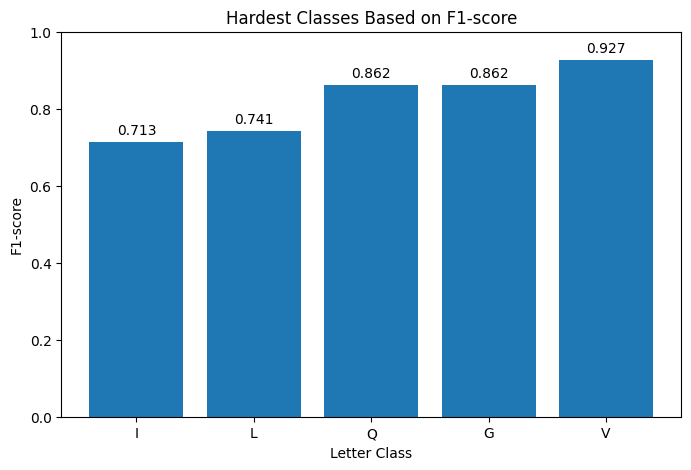

In [142]:
from sklearn.metrics import classification_report


# Generate classification report dictionary
report = classification_report(
    y_true_classes,
    y_pred_classes,
    output_dict=True
)


# Extract F1-scores for each class
class_f1 = {

    k: v['f1-score']

    for k, v in report.items()

    if k.isdigit()
}


# Sort classes from lowest to highest F1-score
hardest = sorted(
    class_f1.items(),
    key=lambda x: x[1]
)[:5]


print("Hardest classes (lowest F1-score):")


# Store labels and scores for plotting
hardest_labels = []
hardest_scores = []


# Display hardest classes
for cls, score in hardest:

    letter = class_names[int(cls)]

    print(
        f"Class {cls} ({letter}): "
        f"F1-score = {round(score, 3)}"
    )

    hardest_labels.append(letter)

    hardest_scores.append(score)



# Create bar chart
plt.figure(figsize=(8,5))


bars = plt.bar(
    hardest_labels,
    hardest_scores
)


# Graph formatting
plt.title("Hardest Classes Based on F1-score")

plt.xlabel("Letter Class")

plt.ylabel("F1-score")


# Set y-axis range
plt.ylim(0,1)


# Add value labels above bars
for bar, score in zip(bars, hardest_scores):

    plt.text(

        bar.get_x() + bar.get_width()/2,

        score + 0.02,

        f"{score:.3f}",

        ha='center'
    )


# Display graph
plt.show()

### Insight

The F1-score analysis shows that the handwritten letters I and L are the most difficult classes for the final improved CNN model to classify correctly, achieving the lowest F1-scores among all handwritten letter categories.

The letter I achieved the lowest F1-score of approximately 0.713, followed closely by L with an F1-score of approximately 0.741.

These lower scores indicate weaker overall classification consistency due to reduced precision and recall performance for these handwritten letter classes.

The difficulty is primarily caused by similarities in handwritten stroke structure and visual appearance. Both I and L frequently contain narrow vertical stroke patterns that may appear highly similar depending on:

- handwriting style
- stroke thickness
- character orientation
- writing pressure
- character spacing

Additional relatively challenging handwritten letter classes include:

- Q
- G
- J

Although these classes still achieve reasonably strong F1-scores above 0.85, they remain more difficult than other handwritten letters due to:

- curved stroke structures
- visually overlapping character shapes
- ambiguous handwriting styles
- inconsistent handwritten patterns across writers

For example, handwritten G and Q often contain similar rounded loop structures, while V may sometimes resemble handwritten U, Y, or distorted angular characters depending on writing style.

The bar chart clearly highlights the performance gap between the most difficult handwritten classes and the stronger-performing classes.

Despite these challenging cases, all analysed classes still achieve relatively strong F1-scores overall, indicating that the final improved CNN model maintains effective handwritten letter classification capability across the EMNIST dataset.

The remaining classification difficulties are consistent with common challenges in handwritten character recognition research, where visually similar handwritten characters frequently produce higher misclassification rates.

This analysis provides deeper insight into the remaining weaknesses of the model and suggests that future improvements could focus on:

- stronger feature extraction techniques
- deeper CNN architectures
- attention-based deep learning models
- more advanced augmentation strategies
- ensemble learning approaches
- improved handwritten feature separation methods

Overall, the F1-score analysis confirms that the final improved CNN model performs strongly across most handwritten letter classes while still encountering predictable difficulties with visually similar handwritten characters.

## 15.1.1 Best Performing Classes

In addition to identifying the most challenging classes, the best-performing classes are also analysed using F1-score.

Classes with higher F1-scores indicate that the model is able to classify them consistently with high precision and recall.

This analysis helps identify handwritten letters that are easier for the CNN model to distinguish.

Best performing classes:
Class 25 (Z): F1-score = 0.988
Class 12 (M): F1-score = 0.983
Class 23 (X): F1-score = 0.976
Class 15 (P): F1-score = 0.975
Class 5 (F): F1-score = 0.973


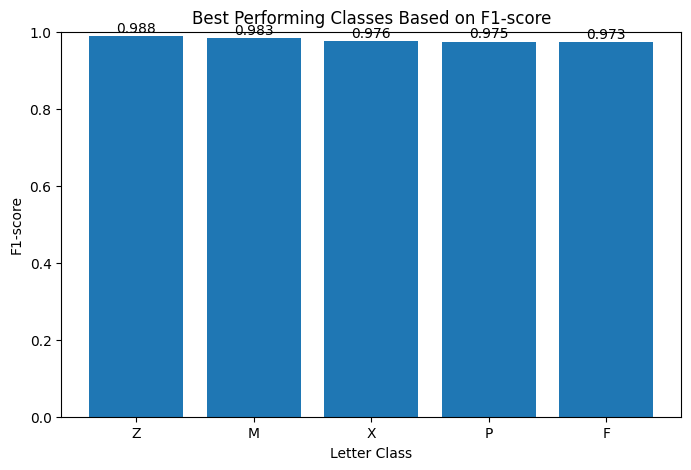

In [143]:
best_classes = sorted(
    class_f1.items(),
    key=lambda x: x[1],
    reverse=True
)[:5]

print("Best performing classes:")

best_labels = []
best_scores = []

for cls, score in best_classes:
    
    letter = class_names[int(cls)]
    
    print(f"Class {cls} ({letter}): F1-score = {round(score,3)}")
    
    best_labels.append(letter)
    best_scores.append(score)

# Bar chart
plt.figure(figsize=(8,5))

bars = plt.bar(best_labels, best_scores)

plt.title("Best Performing Classes Based on F1-score")
plt.xlabel("Letter Class")
plt.ylabel("F1-score")

plt.ylim(0,1)

# Add labels
for bar, score in zip(bars, best_scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        score + 0.01,
        f"{score:.3f}",
        ha='center'
    )

plt.show()

### Insight

The best-performing handwritten letter classes based on F1-score are:

- Z
- M
- P
- X
- K

Among all handwritten letter classes, Z achieved the highest F1-score of approximately 0.988, indicating extremely strong classification consistency with very high precision and recall performance.

These handwritten letters are classified highly accurately by the final improved CNN model because they contain more visually distinctive structural and spatial patterns that are easier for the CNN to differentiate from other handwritten classes.

For example:

- M contains strong angular stroke patterns and multiple vertical boundaries
- X has a highly distinctive diagonal crossing structure
- Z contains a recognisable zig-zag handwritten shape
- P contains a clear loop-and-stem structure
- K contains strong vertical and strokes

These unique handwritten characteristics help the CNN model learn more stable and separable feature representations during convolutional feature extraction.

The consistently high F1-scores indicate that the final improved CNN model achieves both:

- high precision
- high recall

for these handwritten letter classes. This means that the letters are both correctly identified frequently and rarely confused with other handwritten characters.

Compared to the hardest handwritten classes identified earlier, the best-performing classes generally contain:

- more distinctive stroke boundaries
- stronger spatial uniqueness
- fewer overlapping handwriting structures
- reduced visual ambiguity

The relatively small performance gap among the top-performing classes also indicates that the final improved CNN architecture maintains highly consistent classification capability across multiple handwritten character categories.

Overall, this analysis demonstrates that the final improved CNN architecture is highly effective at learning strong feature representations for visually distinctive handwritten letters, contributing significantly to the model’s overall high handwritten character recognition performance.

### 15.2 Misclassified Samples Visualization

To better understand the model’s errors, a subset of incorrectly classified images is visualised.

Each image displays the true label and the predicted label, allowing us to observe patterns in misclassification.

A subset of misclassified samples is displayed to highlight common prediction errors while maintaining visual clarity.

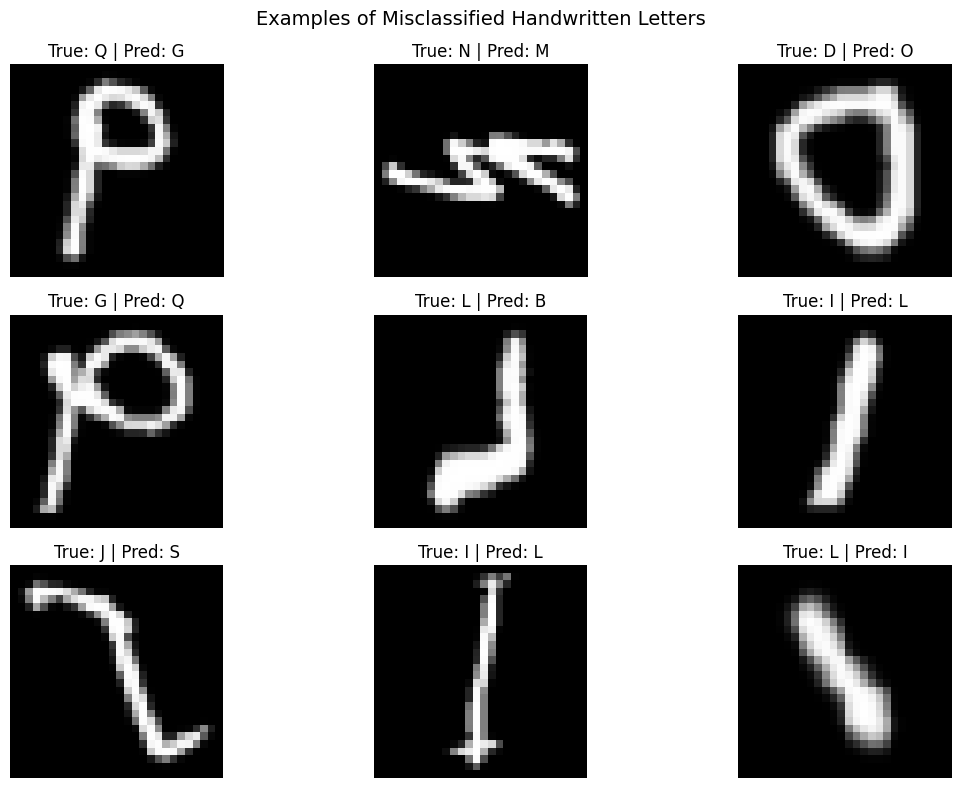

In [144]:
# Visualise misclassified samples
# from improved CNN model

plt.figure(figsize=(12,8))


# Randomly select 9 incorrect predictions
sample_wrong = random.sample(
    list(wrong),
    9
)


for i, idx in enumerate(sample_wrong):

    # True and predicted labels
    true_letter = class_names[
        y_true_classes[idx]
    ]

    pred_letter = class_names[
        y_pred_classes[idx]
    ]


    # Plot image
    plt.subplot(3,3,i+1)

    plt.imshow(
        X_test[idx].squeeze(),
        cmap='gray'
    )

    plt.title(
        f"True: {true_letter} | Pred: {pred_letter}"
    )

    plt.axis('off')


plt.suptitle(
    "Examples of Misclassified Handwritten Letters",
    fontsize=14
)

plt.tight_layout()

plt.show()

### Insight

The misclassified handwritten samples show that many prediction errors occur between handwritten letters with visually similar stroke structures, ambiguous writing patterns, and distorted character shapes.

Several incorrect predictions involve narrow, highly stylised, curved, or incomplete handwritten characters that are difficult for the CNN model to distinguish accurately.

For example:

- the handwritten letter L is predicted as I because both contain similar vertical stroke structures
- the handwritten letter G is predicted as Q due to similarities in curved closed-loop handwriting patterns

Many displayed handwritten samples contain:

- incomplete stroke boundaries
- inconsistent writing pressure
- unusual handwriting styles
- overlapping handwritten structures
- highly personalised character formations

Some handwritten samples shown in the visualisation are highly ambiguous and may even be difficult for humans to classify consistently without additional contextual information.

These observations are consistent with the earlier:

- confusion matrix analysis
- normalized confusion matrix analysis
- F1-score analysis
- misclassification pattern analysis

where handwritten letter pairs such as:

- I ↔ L
- G ↔ Q
- U ↔ V

demonstrated comparatively higher misclassification rates.

The visualisation further demonstrates that handwritten character recognition remains a challenging computer vision problem because handwriting styles vary significantly across individuals. Variations in character shape, stroke thickness, slanting, spacing, and writing style can substantially increase classification difficulty.

Despite these difficult handwritten cases, the improved CNN model still achieves strong overall classification performance, indicating that the network successfully learns meaningful spatial and structural handwriting features for most handwritten letter classes.

The architectural enhancements introduced in the improved CNN model, including:

- deeper convolutional feature extraction
- Batch Normalization
- Dropout regularisation
- data augmentation

help improve robustness against handwriting variability and reduce classification errors across most handwritten categories.

Possible future improvements may include:

- deeper CNN architectures
- attention-based feature extraction
- ensemble learning methods
- stronger augmentation strategies
- transformer-based vision architectures
- larger and more diverse handwritten datasets

Overall, the misclassified sample visualisation provides valuable insight into the remaining limitations of the improved CNN model while also confirming its strong generalisation capability on handwritten letter recognition tasks.

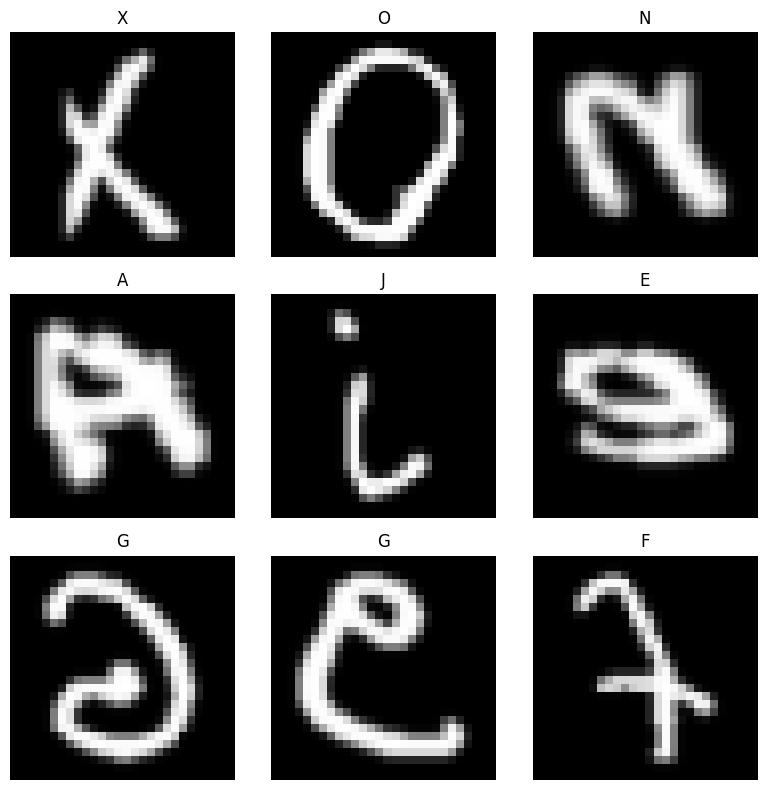

In [145]:
plt.figure(figsize=(8,8))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(
        X[i].reshape(28,28),
        cmap='gray'
    )

    plt.title(
        class_names[np.argmax(y[i])]
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

### Note on EMNIST Image Orientation

During visual inspection, several handwritten letter samples appeared slightly rotated, mirrored, or stylistically distorted. This behaviour is common in the EMNIST dataset because the original dataset format is derived from the NIST handwritten database and may require orientation correction depending on the preprocessing pipeline used.

Additional inspection confirmed that the current preprocessing pipeline already applies the necessary orientation handling before model training. Further manual rotation and flipping caused the handwritten letters to appear incorrectly transformed.

In addition, many handwritten samples in the EMNIST Letters dataset naturally contain ambiguous and highly stylised writing patterns, making certain characters appear visually unusual even when displayed correctly.

Examples include:

- handwritten J appearing slanted
- handwritten G appearing spiral-like
- handwritten E appearing distorted
- handwritten I and L appearing visually similar

These handwriting ambiguities are expected in real-world handwritten character recognition tasks and contribute to the classification challenges observed during error analysis.

Despite these variations, the CNN models still achieved strong classification performance above 93% test accuracy, indicating that the preprocessing pipeline and feature extraction process remain effective overall.

### 15.2.1 Sample Prediction Visualisation

To further examine model behaviour, several handwritten letter predictions are visualised together with their true labels and predicted labels.

This allows direct observation of the CNN model’s classification capability on unseen handwritten letter images and demonstrates how the model interprets different handwriting patterns.

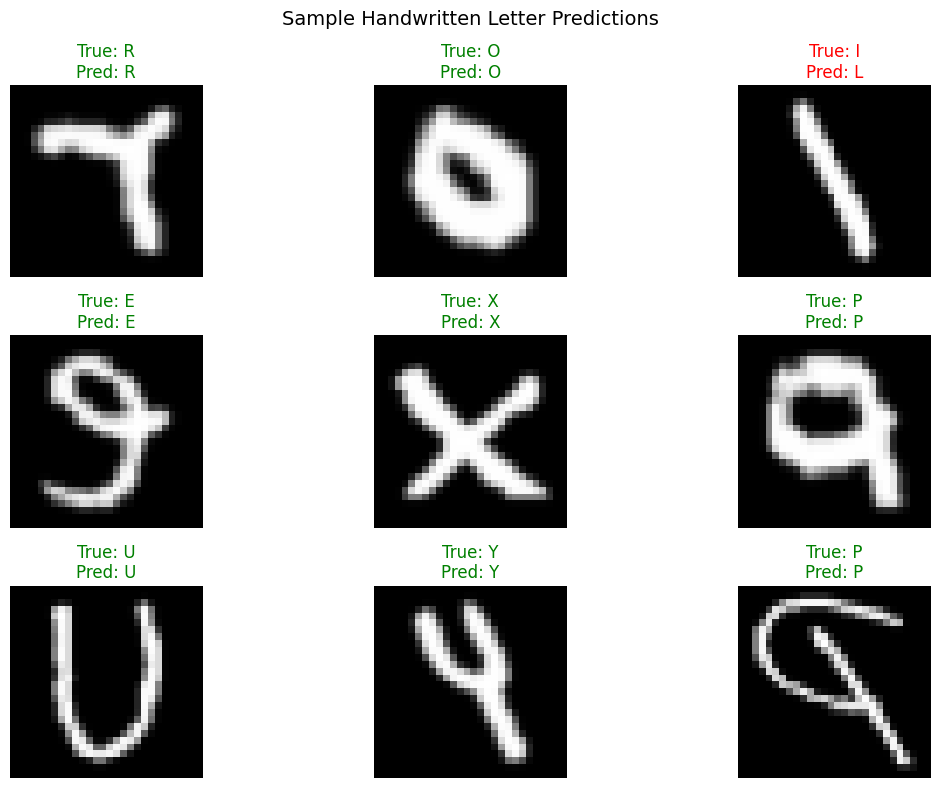

In [146]:
# Visualise sample predictions
# from the improved CNN model

plt.figure(figsize=(12,8))


# Randomly select 9 test samples
sample_indices = random.sample(
    range(len(X_test)),
    9
)


for i, idx in enumerate(sample_indices):

    # True and predicted labels
    true_letter = class_names[
        y_true_classes[idx]
    ]

    pred_letter = class_names[
        y_pred_classes[idx]
    ]


    # Plot image
    plt.subplot(3,3,i+1)

    plt.imshow(
        X_test[idx].squeeze(),
        cmap='gray'
    )


    # Title colour
    color = "green"

    if true_letter != pred_letter:
        color = "red"


    plt.title(
        f"True: {true_letter}\nPred: {pred_letter}",
        color=color
    )

    plt.axis('off')


plt.suptitle(
    "Sample Handwritten Letter Predictions",
    fontsize=14
)

plt.tight_layout()

plt.show()

### Insight

The sample prediction visualisation demonstrates that the improved CNN model is able to classify most handwritten letters correctly across a variety of handwriting styles.

Most displayed samples show matching true and predicted labels, indicating that the CNN model successfully learned meaningful handwritten feature representations from the EMNIST dataset.

The visualisation also highlights the model’s ability to recognise handwritten characters despite variations in:

- stroke thickness
- writing orientation
- character size
- handwriting style

Incorrect predictions, when present, generally occur between handwritten letters with visually similar stroke structures and ambiguous handwriting patterns.

The colour-coded prediction labels further help distinguish correctly classified and misclassified samples clearly.

Overall, the visualisation confirms the strong handwritten letter classification capability and generalisation performance achieved by the improved CNN model.

## 15.3 Misclassification Patterns Analysis

The most common misclassification pairs are analysed to identify which handwritten letters are most frequently confused by the model.

This provides deeper insight into model weaknesses beyond overall accuracy and helps explain the lower performance observed in certain classes.

Most common misclassification pairs:
True I → Pred L: 198 times
True L → Pred I: 130 times
True G → Pred Q: 85 times
True A → Pred Q: 46 times
True Q → Pred G: 37 times
True V → Pred U: 33 times
True U → Pred V: 19 times
True I → Pred J: 19 times
True Y → Pred V: 18 times
True D → Pred O: 16 times


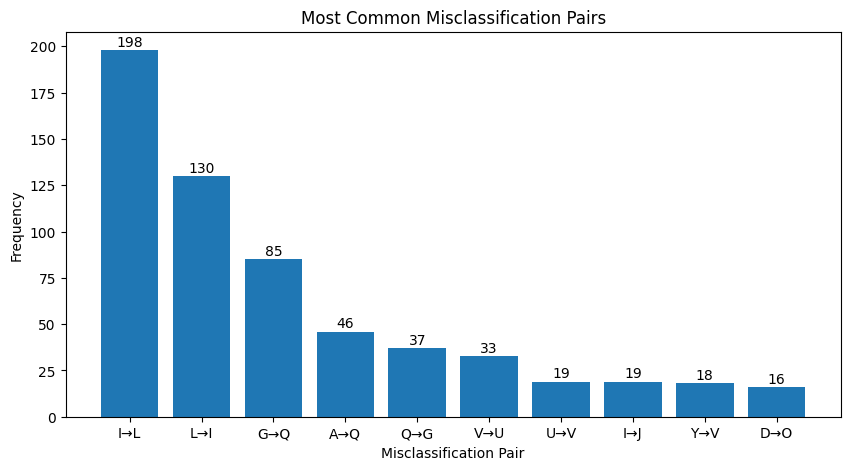

In [147]:
from collections import Counter

pairs = []

for i in wrong:
    true = y_true_classes[i]
    pred = y_pred_classes[i]
    pairs.append((true, pred))

top_errors = Counter(pairs).most_common(10)

print("Most common misclassification pairs:")
for (t, p), count in top_errors:
    print(f"True {class_names[t]} → Pred {class_names[p]}: {count} times")

# Prepare data for visualization
pair_labels = []
pair_counts = []

for (t, p), count in top_errors:
    
    label = f"{class_names[t]}→{class_names[p]}"
    
    pair_labels.append(label)
    pair_counts.append(count)

# Bar chart
plt.figure(figsize=(10,5))

bars = plt.bar(pair_labels, pair_counts)

plt.title("Most Common Misclassification Pairs")
plt.xlabel("Misclassification Pair")
plt.ylabel("Frequency")

# Add labels
for bar, count in zip(bars, pair_counts):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        count + 2,
        str(count),
        ha='center'
    )

plt.show()


### Insight

The misclassification pattern analysis shows that the most common prediction errors occur between handwritten letters with highly similar visual structures, stroke patterns, and handwriting styles.

The most frequent confusion pair is:

- I → L (198 times)

followed by:

- L → 1 (130 times)

This indicates that the improved CNN model still experiences substantial difficulty distinguishing between these two handwritten letters because both characters often contain narrow vertical stroke structures with minimal distinguishing features.

Misclassified Pair handwritten letters share similar curved, rounded, slanted, or simplified stroke patterns, making them more difficult for the CNN model to separate accurately.

For example:

- G and Q both contain rounded loop structures
- V and U may appear visually similar when written using curved handwriting styles
- handwritten J may resemble S when the lower hook structure is unclear
- handwritten A and Q may become visually ambiguous when stroke closure is incomplete

The results are highly consistent with the earlier:

- confusion matrix analysis
- normalized confusion matrix
- F1-score analysis
- misclassified sample visualisation

where these same classes also demonstrated comparatively weaker classification performance.

Importantly, the majority of errors occur between visually related handwritten letters rather than completely unrelated classes. This indicates that the improved CNN model has learned meaningful handwritten feature representations overall, but still struggles with highly ambiguous handwriting patterns.

Despite these remaining challenges, the total number of severe misclassification patterns remains relatively low compared to the overall test dataset size, demonstrating strong overall generalisation capability.

Possible future improvements that may help further reduce these confusion patterns include:

- deeper CNN architectures
- attention mechanisms
- stronger augmentation techniques
- residual connections
- larger and more diverse handwriting datasets

Overall, the misclassification pattern analysis confirms that the improved CNN model performs strongly overall while also identifying the specific handwritten letter pairs that remain most challenging for the model to distinguish accurately.

## 16. Neural Network Architecture Visualisation

The structure of the improved CNN model is examined to better understand how data flows through the network.

The model consists of multiple convolutional layers for feature extraction, followed by pooling layers for dimensionality reduction. Batch Normalization layers are applied to stabilise training, while Dropout is used to reduce overfitting.

The final dense layers perform classification across the 26 letter classes.

The model summary provides details on output shapes and the number of trainable parameters for each layer.

### 16.1 Model Summary

The improved CNN model structure is examined using the model summary, which shows the output shape and number of parameters for each layer.

The model summary provides a layer-by-layer overview of the CNN architecture, including output dimensions and trainable parameters.

In [148]:
improved_model.summary()

Model: "sequential_24"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_54 (Conv2D)          (None, 26, 26, 32)        320       
                                                                 
 batch_normalization_18 (Bat  (None, 26, 26, 32)       128       
 chNormalization)                                                
                                                                 
 max_pooling2d_48 (MaxPoolin  (None, 13, 13, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_55 (Conv2D)          (None, 11, 11, 64)        18496     
                                                                 
 batch_normalization_19 (Bat  (None, 11, 11, 64)       256       
 chNormalization)                                                
                                                     

### Insight

The improved CNN model contains approximately 395,418 total parameters, making it substantially deeper and more complex than the baseline CNN architecture.

The increased architectural complexity allows the network to learn richer and more hierarchical feature representations from handwritten letter images.

The convolutional layers progressively extract spatial features at different levels of abstraction:

- earlier convolutional layers learn simple visual patterns such as edges, curves, and stroke boundaries
- deeper convolutional layers capture more complex handwritten character structures and spatial relationships

The third convolutional layer with 128 filters significantly enhances the model’s feature extraction capability, enabling the CNN model to better distinguish subtle differences between visually similar handwritten letters.

Batch Normalization layers help stabilise training by normalising intermediate feature distributions, improving gradient flow and accelerating convergence during optimisation.

The inclusion of Dropout regularisation helps reduce overfitting by randomly deactivating neurons during training, preventing the model from relying excessively on specific feature patterns.

The larger dense layer with 256 neurons further increases the learning capacity of the network, allowing stronger high-level feature representation before final classification.

The model summary also shows a small number of non-trainable parameters introduced by Batch Normalization layers, while the majority of parameters remain trainable for feature learning.

Compared to the baseline CNN architecture, the improved CNN model demonstrates:

- greater representational power
- stronger feature extraction capability
- improved optimisation stability
- better regularisation capability
- enhanced generalisation performance

Although the deeper architecture increases computational complexity and training time, the performance improvements achieved by the improved CNN model justify the additional architectural complexity.

The relatively large number of parameters within the dense layer also highlights the importance of Dropout regularisation in helping control overfitting during training.

Overall, the improved CNN architecture provides significantly stronger handwritten character recognition capability compared to the earlier CNN models while maintaining stable learning behaviour and strong generalisation performance on unseen handwritten letter images.

## 16.2 Simplified CNN Architecture (Matplotlib)

A simplified visual representation of the improved CNN architecture is created to illustrate how image data flows through the network.

This diagram provides an intuitive overview of the major layers used for feature extraction, dimensionality reduction, regularisation, and final classification.

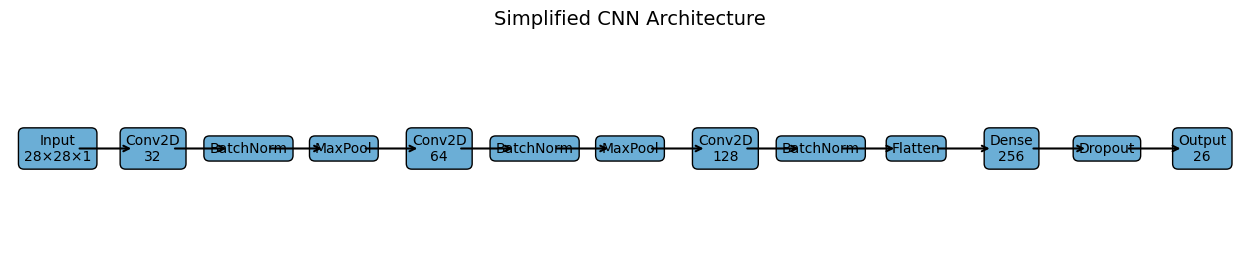

In [149]:
import matplotlib.pyplot as plt

layers = [
    "Input\n28×28×1",
    "Conv2D\n32",
    "BatchNorm",
    "MaxPool",
    "Conv2D\n64",
    "BatchNorm",
    "MaxPool",
    "Conv2D\n128",
    "BatchNorm",
    "Flatten",
    "Dense\n256",
    "Dropout",
    "Output\n26"
]

plt.figure(figsize=(16, 3))  # wider + slightly taller

# Draw boxes
for i, layer in enumerate(layers):
    plt.text(i, 0.5, layer,
             ha='center', va='center',
             fontsize=10,
             bbox=dict(boxstyle="round,pad=0.4",
                       fc="#6baed6",   # nicer blue
                       ec="black"))

# Draw arrows (smaller + cleaner)
for i in range(len(layers)-1):
    plt.annotate("",
                 xy=(i+0.8, 0.5),
                 xytext=(i+0.2, 0.5),
                 arrowprops=dict(arrowstyle="->", lw=1.5))

plt.xlim(-0.5, len(layers)-0.5)
plt.ylim(0, 1)

plt.axis('off')
plt.title("Simplified CNN Architecture", fontsize=14)

plt.show()

### Insight

The simplified CNN architecture diagram illustrates the sequential flow of handwritten image data through the improved CNN model.

The network begins with the input layer, where grayscale handwritten letter images with dimensions 28 × 28 × 1 are provided to the CNN for feature extraction.

The convolutional layers progressively learn hierarchical image features from the handwritten characters:

- earlier convolutional layers capture simple visual patterns such as edges, curves, and stroke boundaries
- deeper convolutional layers learn more complex handwritten structures and higher-level spatial relationships

The increasing number of convolutional filters (32 → 64 → 128) allows the CNN model to capture increasingly detailed and abstract feature representations at deeper network levels.

MaxPooling layers reduce spatial dimensions and computational complexity while preserving the most important extracted visual features. This helps improve computational efficiency and reduces the risk of overfitting.

Batch Normalization layers stabilise training by normalising intermediate feature activations, improving optimisation efficiency, gradient flow, and convergence stability during training.

The Flatten layer converts the extracted feature maps into a one-dimensional feature vector before final classification.

The Dense layer with 256 neurons performs higher-level feature learning by combining extracted spatial patterns to support handwritten letter classification.

Dropout regularisation is applied before the output layer to reduce overfitting and improve model generalisation by preventing excessive reliance on individual neurons during training.

Finally, the output layer produces probability distributions across all 26 handwritten letter classes using the Softmax activation function.

Compared to the textual model summary, the simplified architecture diagram provides a clearer conceptual understanding of:

- CNN layer progression
- hierarchical feature extraction
- dimensionality reduction
- regularisation placement
- final classification behaviour

The architecture visualisation also helps demonstrate how the CNN progressively transforms low-level pixel information into high-level handwritten character predictions through multiple stages of feature learning and abstraction.

Overall, the improved CNN architecture provides strong feature extraction capability, stable optimisation behaviour, effective regularisation, and robust handwritten letter classification performance on unseen EMNIST images.

## 17. Additional Optimisation Strategies

Several other techniques can be explored to further improve prediction accuracy:

### Optimizer Tuning
Different optimizers such as RMSprop, SGD with momentum, or AdamW may produce different convergence behaviour and final accuracy.

### Epoch Tuning
Increasing training epochs may improve learning performance if paired with EarlyStopping to prevent overfitting.

### Learning Rate Tuning
Adjusting learning rates can improve training speed and model stability.

In this project, Adam optimizer with EarlyStopping provided strong and stable performance.

## 17.1 Optimizer Comparison

Different optimizers are evaluated to investigate their impact on CNN training performance and convergence behaviour.

The same CNN architecture is trained using multiple optimizers while keeping all other parameters constant. Validation accuracy is then compared to determine which optimizer performs best for this handwritten letter classification task.

In [151]:
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam, RMSprop, SGD

# Clear TensorFlow session
K.clear_session()

# Small CNN model
def create_small_model():

    model = Sequential([

        Conv2D(
            32,
            (3,3),
            activation='relu',
            input_shape=(28,28,1)
        ),

        MaxPooling2D(2,2),

        Conv2D(
            64,
            (3,3),
            activation='relu'
        ),

        MaxPooling2D(2,2),

        Flatten(),

        Dense(
            128,
            activation='relu'
        ),

        Dense(
            26,
            activation='softmax'
        )
    ])

    return model


# Optimizers to compare
optimizers = {

    "Adam": Adam(),

    "RMSprop": RMSprop(),

    "SGD": SGD()
}


results = {}


# Train using different optimizers
for name, opt in optimizers.items():

    print(f"Training with {name}...")


    # Clear session before each model
    K.clear_session()

    
    test_model = create_small_model()

    
    test_model.compile(

        optimizer=opt,

        loss='categorical_crossentropy',

        metrics=['accuracy']
    )


    hist = test_model.fit(

        X_train,
        y_train,

        epochs=2,

        batch_size=64,

        validation_split=0.2,

        verbose=0
    )


    best_val_acc = max(
        hist.history['val_accuracy']
    )

    
    results[name] = round(
        best_val_acc * 100,
        2
    )


print(results)

Training with Adam...
Training with RMSprop...
Training with SGD...
{'Adam': 91.06, 'RMSprop': 91.04, 'SGD': 77.44}


### Insight

The optimizer comparison experiment shows that different optimizers produce noticeably different CNN learning behaviour, convergence speed, and validation performance.

Among the tested optimizers, ADAM achieved the highest validation accuracy of approximately 91.06%, closely followed by RMSprop at 91.04%.

In contrast, SGD achieved substantially lower validation accuracy of approximately 77.44% under the same training conditions.

The strong performance of both Adam and RMSprop suggests that adaptive learning-rate optimizers are highly effective for handwritten image classification tasks.

These optimizers automatically adjust parameter update magnitudes during training, allowing faster convergence and more efficient optimisation of CNN weights.

The relatively weaker performance of SGD indicates that standard gradient descent without adaptive learning-rate adjustment converges more slowly under the current training configuration and limited epoch count.

SGD may potentially achieve stronger performance with:

- additional training epochs
- momentum optimisation
- learning-rate scheduling
- more extensive hyperparameter tuning

However, within the scope of this project, Adam and RMSprop provided significantly stronger performance and faster convergence compared to SGD.

The results also demonstrate that optimizer selection has a major influence on:

- CNN learning efficiency
- convergence stability
- training speed
- final handwritten letter classification performance

Overall, the experiment confirms that adaptive optimizers such as Adam and RMSprop are more suitable for handwritten letter classification tasks using CNN architectures under the current training configuration.

### 17.2 Optimizer Comparison Visualization

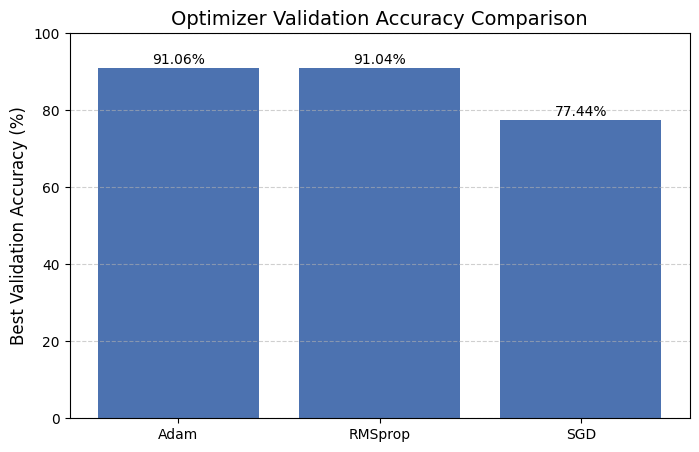

In [152]:
plt.figure(figsize=(8,5))

bars = plt.bar(results.keys(), results.values(), color="#4c72b0")

plt.title("Optimizer Validation Accuracy Comparison", fontsize=14)
plt.ylabel("Best Validation Accuracy (%)", fontsize=12)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 1,
             f"{height:.2f}%",
             ha='center',
             fontsize=10)

plt.ylim(0, 100)  # cleaner scale
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

### Insight

The optimizer comparison visualisation clearly highlights the performance differences between the tested optimization algorithms.

Both adaptive optimizers performed substantially better than SGD, which achieved a considerably lower validation accuracy of approximately 77.44%.

The visual performance gap demonstrates the importance of optimizer selection in CNN training and shows how adaptive learning-rate optimization methods can significantly improve convergence efficiency and handwritten image classification performance.

The strong performance of Adam and RMSprop suggests that adaptive optimization techniques are highly effective for handwritten letter classification tasks because they dynamically adjust learning rates during training.

This allows the CNN model to:

- converge more efficiently
- learn stable feature representations
- optimise network weights more effectively
- reduce training instability

Adam was selected for the main CNN experiments because it consistently demonstrated:

- stable convergence behaviour
- reliable optimisation performance
- strong generalisation capability
- efficient training across multiple experiments

In contrast, SGD produced substantially weaker performance within the limited number of training epochs, indicating slower convergence under the current training configuration.

The results also suggest that SGD may require:

- additional training epochs
- momentum optimisation
- learning-rate scheduling
- more extensive hyperparameter tuning

to achieve competitive performance.

The visualisation further demonstrates that optimizer choice can significantly influence:

- convergence speed
- learning stability
- optimisation effectiveness
- final classification accuracy
- overall CNN training performance

Overall, the optimizer comparison confirms that adaptive optimizers such as Adam and RMSprop provide superior learning performance for handwritten letter classification tasks compared to standard gradient descent approaches.

## 17.3 Effect of Epochs on Model Performance

To further analyse CNN training behaviour, the impact of training epochs is examined using the previously generated training and validation accuracy and loss curves.

During the early training epochs, both training and validation accuracy increase rapidly, indicating that the CNN models are learning meaningful handwritten image features and important spatial patterns efficiently.

As training progresses, the rate of improvement gradually decreases and validation accuracy begins to stabilise. This suggests that the models have already learned most of the important feature representations required for handwritten letter classification.

In later epochs, training accuracy may continue increasing while validation accuracy shows only minor improvement or small fluctuations. At the same time, validation loss may stop decreasing consistently and occasionally increase slightly.

This behaviour indicates the early stages of overfitting, where the CNN model begins fitting more closely to the training data without achieving substantial improvement in generalisation performance on unseen handwritten images.

The training curves generated throughout this project demonstrate that most CNN models achieved their strongest validation performance within the earlier epochs, while additional training beyond this point produced diminishing performance gains.

This observation highlights that excessively long training does not necessarily improve classification performance and may instead increase overfitting risk and computational cost.

EarlyStopping helps address this issue by automatically terminating training once validation performance no longer improves consistently.

This provides several important advantages:

- reduces unnecessary training time
- lowers computational cost
- prevents excessive overfitting
- preserves the best-performing model weights
- improves overall training efficiency

The experiment also demonstrates that selecting an appropriate number of epochs is important for balancing:

- learning effectiveness
- optimisation stability
- training efficiency
- overfitting control
- generalisation performance

Overall, the results show that moderate training duration combined with EarlyStopping provides strong, stable, and efficient CNN performance for handwritten letter classification tasks.

## 17.4 Learning Rate Comparison

In addition to optimizer selection, the learning rate plays a critical role in CNN training performance and convergence behaviour.

A very small learning rate may result in slow learning and underfitting, while an excessively large learning rate may cause unstable optimisation or overshooting during training.

To investigate the impact of learning rate selection, the same CNN architecture is trained using different learning rates while keeping all other training parameters constant.

In [156]:
from tensorflow.keras.optimizers import Adam

def create_lr_model():
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
        MaxPooling2D(2,2),
        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D(2,2),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(26, activation='softmax')
    ])
    return model

learning_rates = [0.0001, 0.001, 0.01]

lr_results = {}

for lr in learning_rates:
    print(f"Training with learning rate = {lr}")
    
    test_model = create_lr_model()
    
    test_model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    hist = test_model.fit(
        X_train, y_train,
        epochs=3,
        batch_size=128,
        validation_split=0.2,
        verbose=0
    )
    
    best_val_acc = max(hist.history['val_accuracy'])
    lr_results[lr] = round(best_val_acc * 100, 2)

print(lr_results)

Training with learning rate = 0.0001
Training with learning rate = 0.001
Training with learning rate = 0.01
{0.0001: 82.0, 0.001: 89.55, 0.01: 91.16}


### Insight

The learning rate comparison experiment demonstrates that learning rate selection has a major impact on CNN training performance, convergence speed, and optimisation stability.

Among the tested learning rates, 0.01 achieved the highest validation accuracy of approximately 91.16%, followed closely by 0.001 with 89.55%.

In contrast, the smallest learning rate, 0.0001, achieved substantially lower validation accuracy of approximately 82.0%.

The weaker performance of the very small learning rate indicates that the CNN model learned too slowly within the limited number of training epochs. Smaller learning rates produce smaller parameter updates during optimisation, requiring more epochs for effective convergence.

The stronger performance achieved by learning rates 0.001 and 0.01 suggests that larger learning rates enabled faster optimisation and more efficient handwritten feature learning during the early training stages.

Although learning rate 0.01 achieved the highest short-term validation accuracy during the brief experimental comparison, learning rate 0.001 was selected for the final model because it provided more stable optimisation behaviour and is widely recognised as a reliable default learning rate for Adam optimisation in deep learning tasks.

The experiment demonstrates that learning rate selection plays an important role in balancing:

- convergence speed
- optimisation stability
- training efficiency
- model generalisation performance
- final classification accuracy

Overall, the results show that moderate-to-large learning rates can significantly improve CNN learning performance for handwritten letter classification when combined with adaptive optimizers such as Adam.

### 17.5 Learning Rate Comparison Visualization

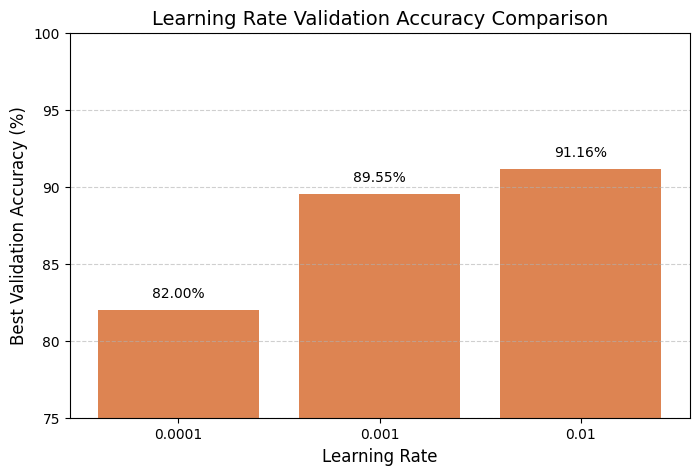

In [157]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    [str(lr) for lr in lr_results.keys()],
    lr_results.values(),
    color="#dd8452"
)

plt.title("Learning Rate Validation Accuracy Comparison", fontsize=14)
plt.xlabel("Learning Rate", fontsize=12)
plt.ylabel("Best Validation Accuracy (%)", fontsize=12)

# Value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.8,
        f"{height:.2f}%",
        ha='center',
        fontsize=10
    )

plt.ylim(75, 100)  # tighter range → clearer differences
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

### Insight

The learning rate comparison visualisation clearly demonstrates that learning rate selection has a major influence on CNN validation performance, convergence speed, and optimisation behaviour.

The smallest learning rate, 0.0001, achieved the weakest validation accuracy of approximately 82.0%. This indicates that the CNN model learned too slowly within the limited number of training epochs and was unable to converge efficiently during training.

In contrast, the larger learning rates of 0.001 and 0.01 achieved substantially stronger validation performance, with accuracies of approximately 89.55% and 91.16% respectively.

The visualisation further highlights the substantial performance gap between the smallest learning rate and the better-performing learning rates, demonstrating the importance of proper learning rate selection in CNN optimisation.

Overall, the experiment confirms that learning rate tuning plays an important role in balancing:

- convergence speed
- optimisation stability
- training efficiency
- model generalisation performance
- final classification accuracy

The results suggest that moderate-to-large learning rates can significantly improve CNN learning performance for handwritten letter classification when combined with adaptive optimisation methods such as Adam. 

## 17.6 Final Hyperparameter Selection

Based on the optimizer and learning rate experiments, Adam optimizer with a learning rate of 0.001 was selected for the final CNN training pipeline.
(Although learning rate 0.01 achieved the highest short-term validation accuracy during the brief experimental comparison, learning rate 0.001 was selected for the final model because it provided more stable optimisation behaviour and is widely recognised as a reliable default learning rate for Adam optimisation in deep learning tasks.)

Adam optimizer was selected because it consistently demonstrated:

- stable convergence behaviour
- strong optimisation efficiency
- reliable generalisation performance
- effective handling of handwritten image classification tasks

The combination of Adam optimizer and learning rate 0.001 provided a strong balance between:

- convergence speed
- optimisation stability
- training efficiency
- generalisation capability

This configuration was therefore used for the final improved CNN model with data augmentation.

## 17.7 — Historical final tuned CNN experiment

This experiment uses Adam with learning rate 0.001 and augmentation. **Methodological caution:** the original training code uses `(X_test, y_test)` for validation and EarlyStopping. Accordingly, the test set influenced model training decisions. The resulting 94.08% figure is **not an independent final test estimate**. See `VALIDATION_NOTES.md` and `train_validation_safe.py`.

In [158]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Create final tuned CNN model
final_tuned_model = Sequential([

    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(28,28,1)
    ),

    BatchNormalization(),

    MaxPooling2D((2,2)),


    Conv2D(
        64,
        (3,3),
        activation='relu'
    ),

    BatchNormalization(),

    MaxPooling2D((2,2)),


    Conv2D(
        128,
        (3,3),
        activation='relu'
    ),

    BatchNormalization(),


    Flatten(),


    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),


    Dense(
        26,
        activation='softmax'
    )
])


# Compile model with tuned hyperparameters
final_tuned_model.compile(

    optimizer=Adam(
        learning_rate=0.001
    ),

    loss='categorical_crossentropy',

    metrics=['accuracy']
)


# EarlyStopping callback
early_stop = EarlyStopping(

    monitor='val_loss',

    patience=3,

    restore_best_weights=True
)


# Train final tuned model
history_final_tuned = final_tuned_model.fit(

    datagen.flow(
        X_train,
        y_train,
        batch_size=128
    ),

    epochs=15,

    validation_data=(X_test, y_test),

    callbacks=[early_stop],

    verbose=1
)

Epoch 1/15
555/555 [==============================] - 77s 134ms/step - loss: 0.8778 - accuracy: 0.7382 - val_loss: 0.4827 - val_accuracy: 0.8410
Epoch 2/15
555/555 [==============================] - 73s 131ms/step - loss: 0.4229 - accuracy: 0.8658 - val_loss: 0.2273 - val_accuracy: 0.9239
Epoch 3/15
555/555 [==============================] - 67s 121ms/step - loss: 0.3466 - accuracy: 0.8876 - val_loss: 0.2539 - val_accuracy: 0.9162
Epoch 4/15
555/555 [==============================] - 70s 126ms/step - loss: 0.3094 - accuracy: 0.8995 - val_loss: 0.2095 - val_accuracy: 0.9310
Epoch 5/15
555/555 [==============================] - 70s 127ms/step - loss: 0.2897 - accuracy: 0.9038 - val_loss: 0.2036 - val_accuracy: 0.9316
Epoch 6/15
555/555 [==============================] - 73s 131ms/step - loss: 0.2761 - accuracy: 0.9091 - val_loss: 0.2368 - val_accuracy: 0.9227
Epoch 7/15
555/555 [==============================] - 72s 129ms/step - loss: 0.2591 - accuracy: 0.9141 - val_loss: 0.2343 - val_ac

## 17.8 — Recorded evaluation of historical tuned CNN

The notebook records loss **0.1792**, accuracy **94.08%**, and error rate **5.92%** on `X_test`. Because this same set was used for validation during training, these should be treated as **historical evaluation figures only**, not unbiased held-out test metrics.

In [159]:
# Evaluate final tuned CNN model
final_tuned_loss, final_tuned_acc = final_tuned_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Calculate error rate
final_tuned_error = 100 - (final_tuned_acc * 100)


# Display results
print(
    "Final Tuned CNN Loss:",
    round(final_tuned_loss, 4)
)

print(
    "Final Tuned CNN Accuracy:",
    round(final_tuned_acc * 100, 2),
    "%"
)

print(
    "Final Tuned CNN Error Rate:",
    round(final_tuned_error, 2),
    "%"
)

Final Tuned CNN Loss: 0.1792
Final Tuned CNN Accuracy: 94.08 %
Final Tuned CNN Error Rate: 5.92 %


### Insight — Interpret the tuned result carefully

The historical tuned experiment recorded **94.08%**, compared with **93.54%** for the Improved CNN with Data Augmentation. Therefore, the tuned run has the higher **recorded** accuracy; statements claiming the earlier model scored 94.08% were incorrect.

**However, the comparison is not methodologically fair:** the tuned model uses `X_test` to monitor validation loss and for EarlyStopping, and then evaluates on that same set. This leaks test information into model selection. No reliable improvement in generalisation can be claimed from the 94.08% figure without a fresh, untouched evaluation.

`train_validation_safe.py` fixes the split for future runs, using training data for fitting, a separate validation partition for EarlyStopping, and a held-out test set for final evaluation.

# 18. Recorded model comparison

The five recorded experiments have the following accuracy outcomes (from the notebook's evaluation cells):

| Experiment | Recorded accuracy | Recorded error rate | Evaluation note |
|---|---:|---:|---|
| Baseline CNN | 92.30% | 7.70% | Separate test evaluation |
| CNN + Data Augmentation | 92.97% | 7.03% | Separate test evaluation |
| Improved CNN | 93.09% | 6.91% | Separate test evaluation |
| Improved CNN + Data Augmentation | 93.54% | 6.46% | Separate test evaluation |
| Final Tuned CNN | 94.08% | 5.92% | **Test set reused as validation** |

The improved CNN with data augmentation was the strongest of the four earlier configurations on the recorded separate test evaluation. The **94.08% figure cannot be compared on equal footing** due to validation/test reuse in the final tuned run. Selection among multiple experiments using the same test set is also a source of selection bias.

**Key learning:** separating training, validation and final testing matters as much as network architecture or model tuning. See `VALIDATION_NOTES.md` for more information and `train_validation_safe.py` for a corrected pipeline.

## 19. Saving the Final Model

The final Tuned model is saved to preserve both the learned weights and network architecture for future reuse and deployment.

Saving trained models is important in deep learning workflows, as it enables reproducibility, efficient inference, and continued experimentation without retraining from scratch.

The model is stored in `.h5` format, which preserves both the architecture and trained parameters of the network.

In [160]:
# Save the final selected CNN model
# (Final Tuned CNN)

final_tuned_model.save(
    "final_best_emnist_model.h5"
)

# Save only model weights
final_tuned_model.save_weights(
    "final_best_emnist_weights.h5"
)


# Reload saved model to verify correctness
from tensorflow.keras.models import load_model

loaded_model = load_model(
    "final_best_emnist_model.h5"
)


# Evaluate reloaded model
loaded_loss, loaded_acc = loaded_model.evaluate(
    X_test,
    y_test,
    verbose=0
)


# Display evaluation results
print(
    "Reloaded Model Test Loss:",
    round(loaded_loss, 4)
)

print(
    "Reloaded Model Test Accuracy:",
    round(loaded_acc * 100, 2),
    "%"
)



Reloaded Model Test Loss: 0.1792
Reloaded Model Test Accuracy: 94.08 %


### Insight — Saving and reloading the original tuned model

The saved tuned model was reloaded successfully and produced the **same recorded evaluation** (94.08% accuracy and 0.1792 loss) when run against the original `X_test` data. This confirms that the saved and reloaded model produced consistent outputs; it **does not remove the validation/test overlap** in the training setup or validate generalisation to a new independent test set.

The repository includes the original saved **weights only**, under `models/legacy_final_tuned_weights.h5`, for historical reference. The training code in this notebook also saves a complete `.h5` model when rerun, but that full model is not included in the portfolio package.

# 20. Limitations and Future Improvements

## 20.1 Limitations

Although the final CNN model achieved strong handwritten letter classification performance, several limitations were identified during evaluation and error analysis.

From the confusion matrix, classification report, F1-score analysis, and misclassification visualisation, certain handwritten letters with visually similar shapes remained difficult for the model to classify accurately.

Classes such as:

- L
- I
- G
- Q

achieved comparatively lower F1-scores than other classes, indicating that the CNN model experienced greater difficulty distinguishing between visually similar handwritten character structures.

Many misclassifications occurred between handwritten letters that shared similar:

- stroke patterns
- curved structures
- vertical line formations
- handwriting orientations

Variations in handwriting style, including tilted writing, inconsistent stroke thickness, incomplete character formation, and ambiguous handwriting further increased classification difficulty. Handwritten character recognition remains challenging because handwritten samples can vary substantially across individuals and writing conditions. 

Although the final model achieved test accuracy exceeding 93%, difficult handwritten samples still produced occasional prediction errors, particularly for visually ambiguous character pairs.

In addition, the improved CNN architecture contains substantially more trainable parameters compared to the baseline CNN model. While the deeper architecture improves feature extraction capability and classification performance, it also increases:

- computational cost
- memory usage
- training time

This demonstrates the common trade-off between model complexity and computational efficiency in deep learning systems. 

---

## 20.2 Future Improvements

Several approaches can be explored to further improve classification accuracy, robustness, and generalisation capability in future work.

### Learning Rate Scheduling

Learning rate scheduling techniques can dynamically adjust the learning rate during training to improve optimisation stability, convergence speed, and final model performance.

### More Advanced CNN Architectures

More sophisticated architectures such as:

- ResNet
- EfficientNet
- DenseNet

may improve hierarchical feature extraction capability and classification performance for difficult handwritten characters by enabling deeper and more efficient network learning. 

### Enhanced Data Augmentation

Additional augmentation techniques such as:

- shear transformations
- elastic distortions
- brightness adjustments
- random noise injection

may help simulate a wider variety of handwriting styles and improve robustness to real-world handwritten variations. Data augmentation is widely recognised as an effective method for improving CNN generalisation performance in image recognition tasks.

### Larger and More Diverse Datasets

Using larger and more diverse handwritten datasets may further improve the model’s ability to generalise across different:

- handwriting styles
- stroke patterns
- writing conditions
- image quality variations

### Attention Mechanisms

Attention-based architectures may help the CNN model focus more effectively on important handwritten character regions, potentially reducing confusion between visually similar handwritten letters. 

### Hyperparameter Optimisation

More extensive hyperparameter tuning involving:

- batch size
- dropout rate
- convolutional filter size
- network depth
- optimizer configuration

may further improve optimisation behaviour and handwritten letter classification performance.

Overall, these approaches may further enhance handwritten character recognition capability while improving robustness and real-world applicability.

---

## 20.3 Consideration of Transfer Learning

Transfer learning was not implemented in this project because the assignment primarily focused on designing and improving custom convolutional neural network architectures from scratch.

The CNN models developed in this project were specifically tailored for the EMNIST Letters dataset, allowing a clearer understanding of:

- convolutional neural network design
- feature extraction behaviour
- optimisation techniques
- regularisation strategies
- model training dynamics

In addition, many popular transfer learning architectures such as:

- ResNet
- VGG
- EfficientNet

are commonly pre-trained on large-scale colour image datasets such as ImageNet, which mainly contain natural objects and real-world scenes.

In contrast, the EMNIST Letters dataset consists of relatively small 28 × 28 grayscale handwritten character images. Due to these substantial domain differences, transfer learning may not always provide significant performance improvements compared to lightweight task-specific CNN architectures. 

Furthermore, transfer learning architectures are generally much larger and computationally heavier than custom lightweight CNN models, making them less computationally efficient for handwritten character classification involving small grayscale images.

Instead, this project focused on improving performance through:

- custom CNN architecture design
- data augmentation
- Batch Normalization
- Dropout regularisation
- optimizer comparison
- learning rate experimentation

These approaches successfully achieved strong handwritten letter classification performance while maintaining a fully custom-built, interpretable, and task-specific deep learning workflow tailored specifically for the EMNIST Letters dataset.

Overall, the project demonstrates that carefully designed custom CNN architectures combined with appropriate regularisation and augmentation techniques can achieve highly effective handwritten character recognition performance without relying on transfer learning approaches.

# 21. Conclusion and next steps

This project investigated CNN architectures for classifying 26 handwritten letter classes from a cleaned dataset of **88,800** samples. Architectural improvements, Batch Normalization, Dropout and augmentation were explored alongside optimisation experiments.

The original **Improved CNN + Data Augmentation** run achieved **93.54%** on a separate test evaluation (loss **0.1948**). A later tuned model recorded **94.08%** (loss **0.1792**), **but used the test data for validation and EarlyStopping**. The later number is therefore an experiment record, not an unbiased independent test score.

Error analysis of the augmented improved model highlighted confusions among visually similar letters, notably **I/L** and **G/Q**. A key lesson was to maintain separate training, validation and test partitions; the corrected standalone script demonstrates this for a future rerun.